# Noise Investigation: Effect of Noisy Training Data on Machine Learning Generalization

**Dataset:** HTRU2 pulsar classification dataset  
**Models:** Logistic Regression and K-Nearest Neighbors (KNN)

This notebook evaluates how controlled feature noise and label noise introduced into the **training data** affect model generalization. The test set is kept clean and fixed throughout the experiment. Each noise condition is evaluated over repeated noise realizations using the same stratified train/test split.

The primary performance measures are Accuracy, Precision, Recall, F1 Score, and ROC-AUC, with particular emphasis on F1 Score because the HTRU2 dataset is class-imbalanced.

In [1]:
!pip install ucimlrepo

In [2]:
# ============================================================
# NOISE INVESTIGATION
# HTRU2 PULSAR CLASSIFICATION
#
# Research question:
# How does noisy training data affect machine learning generalization?
#
# EXPERIMENTAL DESIGN
#
# Dataset        : HTRU2
# Models         : Logistic Regression, KNN
# Feature noise  : 0%, 2%, 5%, 10%, 15%, 20%, 30%
# Label noise    : 0%, 2%, 4%, 6%, 8%, 10%
# Repetitions    : 10 per condition using different random seeds
# Test set       : fixed and clean throughout
#
# Feature noise:
#   Gaussian perturbation scaled by each feature's standard deviation
#
# Label noise:
#   Equal numbers of 0->1 and 1->0 flips
#   so the class distribution is preserved exactly.
#
# Metrics:
#   Accuracy, Precision, Recall, F1, ROC-AUC
# ============================================================


## Research Question and Experimental Scope

**Research question:** How does noisy training data affect machine learning generalization?

Two forms of training-data corruption are investigated:

- **Feature noise:** zero-mean Gaussian perturbations are added to the training features, with the perturbation scale defined relative to each feature's standard deviation.
- **Label noise:** a controlled, symmetric fraction of training labels is flipped, with equal numbers of 0→1 and 1→0 flips so that the training class counts remain unchanged.

The tested feature-noise levels are **0%, 2%, 5%, 10%, 15%, 20%, and 30%**. The tested label-noise levels are **0%, 2%, 4%, 6%, 8%, and 10%**. Each condition is evaluated using **10 repetitions** with different random seeds. At 0% noise, the repetitions are identical because no perturbation is applied.

A supplementary transition diagnostic evaluates label-noise levels of **6%, 8%, 8.5%, 9%, 9.5%, and 10%** to examine the rapid change in performance near the upper end of the tested range.

**Important:** a feature-noise percentage and a label-noise percentage represent different quantities. Feature-noise percentage specifies the Gaussian perturbation scale relative to feature variability, whereas label-noise percentage specifies the fraction of training labels flipped.

### 1. Import Libraries

In [3]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)
from scipy.stats import levene, t
from IPython.display import display


In [4]:
from pathlib import Path

REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
FIGURES_DIR = REPO_ROOT / "figures"
RESULTS_DIR = REPO_ROOT / "results"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("Figures ->", FIGURES_DIR)
print("Results ->", RESULTS_DIR)

Figures -> /content/figures
Results -> /content/results


### 2. Experiment Configuration

In [5]:
# ============================================================
# 2. EXPERIMENT CONFIGURATION
# ============================================================
RANDOM_STATE = 42

# Feature-noise levels
FEATURE_NOISE_LEVELS = [
    0.00,
    0.02,
    0.05,
    0.10,
    0.15,
    0.20,
    0.30
]

# Label-noise levels
#
# Symmetric label noise preserves the original class distribution exactly.
#
# The label-noise range is limited to 10% for the controlled experiment.
#
LABEL_NOISE_LEVELS = [
    0.00,
    0.02,
    0.04,
    0.06,
    0.08,
    0.10
]

# Number of repetitions per condition
N_REPETITIONS = 10

# Test-set proportion
TEST_SIZE = 0.20


def format_noise_percent(level):
    """Keep 8.5% distinct from 8% (do not truncate with int())."""
    pct = level * 100
    rounded = round(pct, 1)
    if abs(rounded - round(rounded)) < 1e-9:
        return f"{int(round(rounded))}%"
    return f"{rounded:.1f}%"


print("=" * 80)
print("NOISE INVESTIGATION")
print("=" * 80)

print("\nFeature noise levels:")
print(
    [format_noise_percent(x) for x in FEATURE_NOISE_LEVELS]
)

print("\nLabel noise levels:")
print(
    [format_noise_percent(x) for x in LABEL_NOISE_LEVELS]
)

print(
    "\nRepetitions per condition:",
    N_REPETITIONS
)

NOISE INVESTIGATION

Feature noise levels:
['0%', '2%', '5%', '10%', '15%', '20%', '30%']

Label noise levels:
['0%', '2%', '4%', '6%', '8%', '10%']

Repetitions per condition: 10


### 3. Load the HTRU2 Dataset

In [6]:
# ============================================================
# 3. LOAD HTRU2 DATASET
# ============================================================
print("\n" + "=" * 80)
print("[3] LOADING HTRU2 DATASET")
print("=" * 80)

htru2 = fetch_ucirepo(id=372)

X = htru2.data.features.copy()

y = htru2.data.targets.copy()

# Convert target DataFrame to Series
if isinstance(y, pd.DataFrame):
    y = y.iloc[:, 0]

# Reset indices
X = X.reset_index(drop=True)
y = y.reset_index(drop=True)

print("\nDataset shape:")
print("X:", X.shape)
print("y:", y.shape)

print("\nFeature names:")
print(list(X.columns))

print("\nOriginal class distribution:")
print(
    y.value_counts()
    .sort_index()
)

print("\nOriginal class percentages:")
print(
    (
        y.value_counts(
            normalize=True
        )
        .sort_index()
        * 100
    ).round(2)
)


[3] LOADING HTRU2 DATASET

Dataset shape:
X: (17898, 8)
y: (17898,)

Feature names:
['Profile_mean', 'Profile_stdev', 'Profile_skewness', 'Profile_kurtosis', 'DM_mean', 'DM_stdev', 'DM_skewness', 'DM_kurtosis']

Original class distribution:
class
0    16259
1     1639
Name: count, dtype: int64

Original class percentages:
class
0    90.84
1     9.16
Name: proportion, dtype: float64


### 4. Validate the Dataset

In [7]:
# ============================================================
# 4. BASIC DATA VALIDATION
# ============================================================
print("\n" + "=" * 80)
print("[4] BASIC DATA VALIDATION")
print("=" * 80)

print(
    "\nMissing values:",
    X.isnull().sum().sum()
)

print(
    "Duplicate rows:",
    X.duplicated().sum()
)

print(
    "Target missing values:",
    y.isnull().sum()
)

assert X.isnull().sum().sum() == 0
assert y.isnull().sum() == 0


[4] BASIC DATA VALIDATION

Missing values: 0
Duplicate rows: 0
Target missing values: 0


### 5. Create the Train/Test Split

In [8]:
# ============================================================
# 5. TRAIN/TEST SPLIT
# ============================================================
print("\n" + "=" * 80)
print("[5] TRAIN / TEST SPLIT")
print("=" * 80)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

# Reset indices to maintain explicit X/y alignment.
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)

y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print(
    "\nTraining samples:",
    len(X_train)
)

print(
    "Testing samples :",
    len(X_test)
)

print("\nTraining class distribution:")
print(
    y_train.value_counts()
    .sort_index()
)

print("\nTesting class distribution:")
print(
    y_test.value_counts()
    .sort_index()
)


[5] TRAIN / TEST SPLIT

Training samples: 14318
Testing samples : 3580

Training class distribution:
class
0    13007
1     1311
Name: count, dtype: int64

Testing class distribution:
class
0    3252
1     328
Name: count, dtype: int64


### 6. Define the Models

In [9]:
# ============================================================
# 6. DEFINE MODELS
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ])
}

print("Models:")
for name in models:
    print("-", name)


Models:
- Logistic Regression
- KNN


### 7. Define Feature-Noise Procedure

In [10]:
# ============================================================
# 7. FEATURE-NOISE PROCEDURE
# ============================================================
def add_feature_noise(
    X_data,
    noise_level,
    random_state
):
    """
    Add zero-mean Gaussian perturbations independently to the training features.

    For feature j:

        X_noisy[j] =
            X[j] + alpha * std(X[j]) * epsilon

    where:

        epsilon ~ N(0, 1)

    The perturbation scale is therefore relative to the natural
    scale of each feature.
    """

    rng = np.random.default_rng(
        random_state
    )

    X_noisy = X_data.copy()

    for column in X_noisy.columns:

        feature_std = X_data[column].std()

        noise = rng.normal(
            loc=0,
            scale=(
                noise_level
                * feature_std
            ),
            size=len(X_data)
        )

        X_noisy[column] = (
            X_noisy[column]
            + noise
        )

    return X_noisy

### 8. Define Symmetric Label-Noise Procedure

In [13]:
# ============================================================
# 8. SYMMETRIC LABEL-NOISE PROCEDURE
# ============================================================
def add_symmetric_label_noise(
    y_data,
    noise_level,
    random_state
):
    """
    Apply symmetric label noise while preserving
    the training class counts exactly.

    If the requested noise level is p:

        total labels corrupted ≈ p * N

    Half of the corrupted labels go:

        0 -> 1

    and half:

        1 -> 0

    Since the same number move in each direction,
    the final class distribution is unchanged.

    Because HTRU2 is class-imbalanced, the feasible range of
    symmetric label noise is constrained by the minority class size.
    """

    rng = np.random.default_rng(
        random_state
    )

    y_noisy = (
        y_data
        .copy()
        .reset_index(drop=True)
    )

    # Identify the two classes
    class_0_indices = np.where(
    y_noisy.values == 0)[0]

    class_1_indices = np.where(
    y_noisy.values == 1)[0]
    # Determine the requested number of label flips
    total_requested = int(
        round(
            noise_level
            * len(y_noisy)
        )
    )

    # Use equal numbers of flips in each direction
    flips_each_direction = (
        total_requested // 2
    )

    # Confirm that the minority class can support the requested flips.
    if flips_each_direction > len(
        class_1_indices
    ):

        raise ValueError(
            f"Noise level "
            f"{noise_level * 100:.2f}% "
            f"is too high to preserve "
            f"class proportions."
        )

    # Randomly select class-0 samples
    zero_to_one = rng.choice(
        class_0_indices,
        size=flips_each_direction,
        replace=False
    )

    # Randomly select class-1 samples
    one_to_zero = rng.choice(
        class_1_indices,
        size=flips_each_direction,
        replace=False
    )

    # Apply the label flips
    y_noisy.iloc[
        zero_to_one
    ] = 1

    y_noisy.iloc[
        one_to_zero
    ] = 0

    return y_noisy.astype(int)

### 9. Validate the Label-Noise Procedure

In [14]:
# ============================================================
# 9. VALIDATE THE LABEL-NOISE PROCEDURE
# ============================================================
print("\n" + "=" * 80)
print("[9] VERIFYING CONTROLLED LABEL NOISE")
print("=" * 80)

original_class_counts = (
    y_train.value_counts()
    .sort_index()
)

label_verification = []

for noise_level in LABEL_NOISE_LEVELS:

    y_check = add_symmetric_label_noise(
        y_train,
        noise_level,
        random_state=123
    )

    noisy_class_counts = (
        y_check.value_counts()
        .sort_index()
    )

    # Count the labels that changed
    actual_flipped = (
        y_check
        != y_train
    ).sum()

    actual_noise_percentage = (
        actual_flipped
        / len(y_train)
        * 100
    )

    # Verify exact preservation of class counts
    class_counts_preserved = (
        original_class_counts
        .equals(
            noisy_class_counts
        )
    )

    label_verification.append({

        "Requested_Noise_%":
            noise_level * 100,

        "Actual_Noise_%":
            actual_noise_percentage,

        "Class_0":
            noisy_class_counts.loc[0],

        "Class_1":
            noisy_class_counts.loc[1],

        "Class_Counts_Preserved":
            class_counts_preserved
    })


label_verification_df = pd.DataFrame(
    label_verification
)

display(
    label_verification_df.round(4)
)

# VALIDATION CHECK
#
# Stop the experiment if the class counts are not preserved.

assert (
    label_verification_df[
        "Class_Counts_Preserved"
    ].all()
), (
    "Controlled label-noise verification failed. "
    "Class counts were not preserved."
)

print(
    "\n✓ Label-noise verification PASSED."
)

print(
    "✓ Class counts remain unchanged "
    "at every noise level."
)


[9] VERIFYING CONTROLLED LABEL NOISE


,Requested_Noise_%,Actual_Noise_%,Class_0,Class_1,Class_Counts_Preserved
0,0.0,0.0000,13007,1311,True
1,2.0,1.9975,13007,1311,True
2,4.0,3.9950,13007,1311,True
3,6.0,5.9925,13007,1311,True
4,8.0,7.9899,13007,1311,True
5,10.0,10.0014,13007,1311,True



✓ Label-noise verification PASSED.
✓ Class counts remain unchanged at every noise level.


### 10. Define the Evaluation Procedure

In [15]:
# ============================================================
# 10. MODEL EVALUATION
# ============================================================

def evaluate_model(model, X_train_data, y_train_data, X_test_data, y_test_data):
    model.fit(X_train_data, y_train_data)
    y_pred = model.predict(X_test_data)

    results = {
        "Accuracy": accuracy_score(y_test_data, y_pred),
        "Precision": precision_score(y_test_data, y_pred, zero_division=0),
        "Recall": recall_score(y_test_data, y_pred, zero_division=0),
        "F1": f1_score(y_test_data, y_pred, zero_division=0)
    }

    if hasattr(model, "predict_proba"):
        results["ROC-AUC"] = roc_auc_score(
            y_test_data, model.predict_proba(X_test_data)[:, 1]
        )
    else:
        results["ROC-AUC"] = np.nan

    return results


### 11. Establish the Clean Baseline

In [16]:
# ============================================================
# 11. CLEAN BASELINE
# ============================================================
print("\n" + "=" * 80)
print("[11] CLEAN BASELINE")
print("=" * 80)

baseline_results = []

for model_name, model in models.items():

    results = evaluate_model(
        model,
        X_train,
        y_train,
        X_test,
        y_test
    )

    baseline_results.append({

        "Model":
            model_name,

        **results
    })

baseline_df = pd.DataFrame(
    baseline_results
)

print("\nClean baseline performance:")

display(
    baseline_df.round(4)
)


[11] CLEAN BASELINE

Clean baseline performance:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.9796,0.9443,0.8262,0.8813,0.9710
1,KNN,0.9804,0.9329,0.8476,0.8882,0.9516


In [17]:
# ============================================================
# 12. FEATURE-NOISE EXPERIMENT
# ============================================================

import time

feature_results = []

total_runs = len(FEATURE_NOISE_LEVELS) * N_REPETITIONS * len(models)
run_number = 0

print("=" * 70)
print("FEATURE NOISE EXPERIMENT")
print("=" * 70)
print(f"Noise levels : {[f'{x*100:g}%' for x in FEATURE_NOISE_LEVELS]}")
print(f"Repetitions  : {N_REPETITIONS}")
print(f"Models       : {list(models.keys())}")
print(f"Total model trainings: {total_runs}")
print("=" * 70)

experiment_start = time.time()

for noise_level in FEATURE_NOISE_LEVELS:

    print(f"\n{'=' * 70}")
    print(f"FEATURE NOISE LEVEL: {noise_level * 100:g}%")
    print(f"{'=' * 70}")

    level_start = time.time()

    for repetition in range(N_REPETITIONS):

        seed = RANDOM_STATE + repetition + int(noise_level * 10000)

        print(
            f"\n  Repetition {repetition + 1}/{N_REPETITIONS} "
            f"| Seed: {seed}"
        )
        print("  Creating noisy training data...")

        X_train_noisy = add_feature_noise(
            X_train,
            noise_level,
            random_state=seed
        )

        print("  Noisy training data created.")

        for model_name, model in models.items():

            run_number += 1
            model_start = time.time()

            print(
                f"    [{run_number}/{total_runs}] "
                f"Training {model_name}..."
            )

            results = evaluate_model(
                model,
                X_train_noisy,
                y_train,
                X_test,
                y_test
            )

            model_time = time.time() - model_start

            feature_results.append({
                "Noise_Type": "Feature Noise",
                "Noise_Level": noise_level,
                "Noise_Percentage": noise_level * 100,
                "Repetition": repetition + 1,
                "Seed": seed,
                "Model": model_name,
                **results
            })

            print(
                f"    ✓ {model_name} completed "
                f"({model_time:.2f}s) | "
                f"Accuracy={results['Accuracy']:.4f} | "
                f"F1={results['F1']:.4f} | "
                f"ROC-AUC={results['ROC-AUC']:.4f}"
            )

        print(
            f"  ✓ Repetition {repetition + 1}/{N_REPETITIONS} completed "
            f"({time.time() - level_start:.2f}s for this noise level)"
        )

    print(
        f"✓ {noise_level * 100:g}% noise completed "
        f"({time.time() - level_start:.2f}s)"
    )

feature_results_df = pd.DataFrame(feature_results)

print("\n" + "=" * 70)
print("FEATURE NOISE EXPERIMENT COMPLETED")
print("=" * 70)
print(f"Rows generated: {len(feature_results_df)}")
print(f"Total time: {time.time() - experiment_start:.2f}s")
print("=" * 70)

FEATURE NOISE EXPERIMENT
Noise levels : ['0%', '2%', '5%', '10%', '15%', '20%', '30%']
Repetitions  : 10
Models       : ['Logistic Regression', 'KNN']
Total model trainings: 140

FEATURE NOISE LEVEL: 0%

  Repetition 1/10 | Seed: 42
  Creating noisy training data...
  Noisy training data created.
    [1/140] Training Logistic Regression...
    ✓ Logistic Regression completed (0.09s) | Accuracy=0.9796 | F1=0.8813 | ROC-AUC=0.9710
    [2/140] Training KNN...
    ✓ KNN completed (0.26s) | Accuracy=0.9804 | F1=0.8882 | ROC-AUC=0.9516
  ✓ Repetition 1/10 completed (0.36s for this noise level)

  Repetition 2/10 | Seed: 43
  Creating noisy training data...
  Noisy training data created.
    [3/140] Training Logistic Regression...
    ✓ Logistic Regression completed (0.07s) | Accuracy=0.9796 | F1=0.8813 | ROC-AUC=0.9710
    [4/140] Training KNN...
    ✓ KNN completed (0.32s) | Accuracy=0.9804 | F1=0.8882 | ROC-AUC=0.9516
  ✓ Repetition 2/10 completed (0.76s for this noise level)

  Repetition

In [18]:
# ============================================================
# 13. LABEL-NOISE EXPERIMENT
# ============================================================

label_results = []

total_runs = len(LABEL_NOISE_LEVELS) * N_REPETITIONS * len(models)
run_number = 0

print("=" * 70)
print("LABEL NOISE EXPERIMENT")
print("=" * 70)
print(f"Noise levels : {[f'{x*100:g}%' for x in LABEL_NOISE_LEVELS]}")
print(f"Repetitions  : {N_REPETITIONS}")
print(f"Models       : {list(models.keys())}")
print(f"Total model trainings: {total_runs}")
print("=" * 70)

experiment_start = time.time()

for noise_level in LABEL_NOISE_LEVELS:

    print(f"\n{'=' * 70}")
    print(f"LABEL NOISE LEVEL: {noise_level * 100:g}%")
    print(f"{'=' * 70}")

    level_start = time.time()

    for repetition in range(N_REPETITIONS):

        seed = RANDOM_STATE + repetition + int(noise_level * 10000)

        print(
            f"\n  Repetition {repetition + 1}/{N_REPETITIONS} "
            f"| Seed: {seed}"
        )
        print("  Creating noisy training labels...")

        y_train_noisy = add_symmetric_label_noise(
            y_train,
            noise_level,
            random_state=seed
        )

        flipped = (y_train_noisy.values != y_train.values).sum()

        print(
            f"  Noisy labels created | "
            f"Labels changed: {flipped}/{len(y_train)}"
        )

        for model_name, model in models.items():

            run_number += 1
            model_start = time.time()

            print(
                f"    [{run_number}/{total_runs}] "
                f"Training {model_name}..."
            )

            results = evaluate_model(
                model,
                X_train,
                y_train_noisy,
                X_test,
                y_test
            )

            model_time = time.time() - model_start

            label_results.append({
                "Noise_Type": "Label Noise",
                "Noise_Level": noise_level,
                "Noise_Percentage": noise_level * 100,
                "Repetition": repetition + 1,
                "Seed": seed,
                "Model": model_name,
                "Actual_Flipped": int(flipped),
                "Train_Class_0": int((y_train_noisy == 0).sum()),
                "Train_Class_1": int((y_train_noisy == 1).sum()),
                **results
            })

            print(
                f"    ✓ {model_name} completed "
                f"({model_time:.2f}s) | "
                f"Accuracy={results['Accuracy']:.4f} | "
                f"F1={results['F1']:.4f} | "
                f"ROC-AUC={results['ROC-AUC']:.4f}"
            )

        print(
            f"  ✓ Repetition {repetition + 1}/{N_REPETITIONS} completed "
            f"({time.time() - level_start:.2f}s for this noise level)"
        )

    print(
        f"✓ {noise_level * 100:g}% noise completed "
        f"({time.time() - level_start:.2f}s)"
    )

label_results_df = pd.DataFrame(label_results)

print("\n" + "=" * 70)
print("LABEL NOISE EXPERIMENT COMPLETED")
print("=" * 70)
print(f"Rows generated: {len(label_results_df)}")
print(f"Total time: {time.time() - experiment_start:.2f}s")
print("=" * 70)

LABEL NOISE EXPERIMENT
Noise levels : ['0%', '2%', '4%', '6%', '8%', '10%']
Repetitions  : 10
Models       : ['Logistic Regression', 'KNN']
Total model trainings: 120

LABEL NOISE LEVEL: 0%

  Repetition 1/10 | Seed: 42
  Creating noisy training labels...
  Noisy labels created | Labels changed: 0/14318
    [1/120] Training Logistic Regression...
    ✓ Logistic Regression completed (0.05s) | Accuracy=0.9796 | F1=0.8813 | ROC-AUC=0.9710
    [2/120] Training KNN...
    ✓ KNN completed (0.24s) | Accuracy=0.9804 | F1=0.8882 | ROC-AUC=0.9516
  ✓ Repetition 1/10 completed (0.29s for this noise level)

  Repetition 2/10 | Seed: 43
  Creating noisy training labels...
  Noisy labels created | Labels changed: 0/14318
    [3/120] Training Logistic Regression...
    ✓ Logistic Regression completed (0.05s) | Accuracy=0.9796 | F1=0.8813 | ROC-AUC=0.9710
    [4/120] Training KNN...
    ✓ KNN completed (0.23s) | Accuracy=0.9804 | F1=0.8882 | ROC-AUC=0.9516
  ✓ Repetition 2/10 completed (0.57s for this

### 15. Combine Experimental Results


In [19]:
# ============================================================
# 14. RESULT-SCHEMA VALIDATION
# ============================================================

required_common_columns = {
    "Noise_Type", "Noise_Level", "Noise_Percentage",
    "Repetition", "Seed", "Model",
    "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"
}
required_label_columns = {
    "Actual_Flipped", "Train_Class_0", "Train_Class_1"
}
required_transition_columns = {
    "Actual_Flipped", "Original_Pulsar_Count",
    "Pulsars_Flipped", "Pulsars_Surviving",
    "Pulsar_Survival_%", "Pulsar_Flip_%",
    "True_Negatives", "False_Positives",
    "False_Negatives", "True_Positives",
    "Predicted_Positive", "Predicted_Negative"
}

assert required_common_columns.issubset(feature_results_df.columns), (
    "Feature-result schema is missing: "
    + str(sorted(required_common_columns - set(feature_results_df.columns)))
)
assert required_common_columns.union(required_label_columns).issubset(label_results_df.columns), (
    "Label-result schema is missing: "
    + str(sorted(required_common_columns.union(required_label_columns) - set(label_results_df.columns)))
)
print("✓ Feature and label result schemas validated.")

✓ Feature and label result schemas validated.


In [20]:
# ============================================================
# 15. COMBINE EXPERIMENTAL RESULTS
# ============================================================
all_results_df = pd.concat(
    [
        feature_results_df,
        label_results_df
    ],
    ignore_index=True
)

print("\n" + "=" * 80)
print("[15] EXPERIMENT SUMMARY")
print("=" * 80)

print(
    "\nTotal raw result rows:",
    len(all_results_df)
)

expected_rows = (
    (len(FEATURE_NOISE_LEVELS) + len(LABEL_NOISE_LEVELS))
    * N_REPETITIONS
    * len(models)
)

print(
    "Expected rows:",
    expected_rows
)

assert (
    len(all_results_df)
    == expected_rows
)

print(
    "\n✓ Expected number of experimental results obtained."
)


[15] EXPERIMENT SUMMARY

Total raw result rows: 260
Expected rows: 260

✓ Expected number of experimental results obtained.


### 16. Calculate Summary Statistics


In [21]:
# ============================================================
# 16. SUMMARY STATISTICS
# ============================================================
print("\n" + "=" * 80)
print("[16] SUMMARY STATISTICS")
print("=" * 80)

flat_summary = (
    all_results_df
    .groupby(
        [
            "Noise_Type",
            "Noise_Level",
            "Model"
        ]
    )
    .agg(

        Accuracy_Mean=(
            "Accuracy",
            "mean"
        ),

        Accuracy_SD=(
            "Accuracy",
            "std"
        ),

        Precision_Mean=(
            "Precision",
            "mean"
        ),

        Precision_SD=(
            "Precision",
            "std"
        ),

        Recall_Mean=(
            "Recall",
            "mean"
        ),

        Recall_SD=(
            "Recall",
            "std"
        ),

        F1_Mean=(
            "F1",
            "mean"
        ),

        F1_SD=(
            "F1",
            "std"
        ),

        ROC_AUC_Mean=(
            "ROC-AUC",
            "mean"
        ),

        ROC_AUC_SD=(
            "ROC-AUC",
            "std"
        ),

        N=(
            "F1",
            "count"
        )
    )
    .reset_index()
)

flat_summary[
    "Noise_Percentage"
] = (
    flat_summary[
        "Noise_Level"
    ]
    * 100
)

print(
    "\nMean ± standard deviation:"
)

display(
    flat_summary
    .sort_values(
        [
            "Noise_Type",
            "Noise_Level",
            "Model"
        ]
    )
    [
        [
            "Noise_Type",
            "Noise_Percentage",
            "Model",
            "F1_Mean",
            "F1_SD",
            "ROC_AUC_Mean",
            "ROC_AUC_SD"
        ]
    ]
    .round(4)
)


[16] SUMMARY STATISTICS

Mean ± standard deviation:


,Noise_Type,Noise_Percentage,Model,F1_Mean,F1_SD,ROC_AUC_Mean,ROC_AUC_SD
0,Feature Noise,0.0,KNN,0.8882,0.0000,0.9516,0.0000
1,Feature Noise,0.0,Logistic Regression,0.8813,0.0000,0.9710,0.0000
2,Feature Noise,2.0,KNN,0.8885,0.0027,0.9513,0.0014
3,Feature Noise,2.0,Logistic Regression,0.8804,0.0013,0.9710,0.0001
4,Feature Noise,5.0,KNN,0.8874,0.0040,0.9521,0.0016
5,Feature Noise,5.0,Logistic Regression,0.8791,0.0012,0.9711,0.0002
6,Feature Noise,10.0,KNN,0.8874,0.0037,0.9483,0.0038
7,Feature Noise,10.0,Logistic Regression,0.8790,0.0010,0.9708,0.0004
8,Feature Noise,15.0,KNN,0.8856,0.0040,0.9469,0.0034
9,Feature Noise,15.0,Logistic Regression,0.8770,0.0020,0.9705,0.0004


### 17. Calculate 95% Confidence Intervals


In [22]:
# ============================================================
# 17. 95% CONFIDENCE INTERVALS
# ============================================================
flat_summary[
    "F1_SE"
] = (
    flat_summary[
        "F1_SD"
    ]
    /
    np.sqrt(
        flat_summary["N"]
    )
)

flat_summary[
    "F1_DF"
] = (
    flat_summary["N"] - 1
)

flat_summary[
    "F1_T_Critical"
] = t.ppf(
    0.975,
    df=flat_summary["F1_DF"]
)

flat_summary[
    "F1_CI95"
] = (
    flat_summary["F1_T_Critical"]
    * flat_summary["F1_SE"]
)

flat_summary[
    "F1_CI_Lower"
] = (
    flat_summary["F1_Mean"]
    -
    flat_summary["F1_CI95"]
)

flat_summary[
    "F1_CI_Upper"
] = (
    flat_summary["F1_Mean"]
    +
    flat_summary["F1_CI95"]
)


print("\n" + "=" * 80)
print("[17] F1 SCORE WITH 95% T-BASED CONFIDENCE INTERVAL")
print("=" * 80)

display(
    flat_summary
    .sort_values(
        [
            "Noise_Type",
            "Noise_Level",
            "Model"
        ]
    )
    [
        [
            "Noise_Type",
            "Noise_Percentage",
            "Model",
            "F1_Mean",
            "F1_SD",
            "F1_CI_Lower",
            "F1_CI_Upper"
        ]
    ]
    .round(4)
)


[17] F1 SCORE WITH 95% T-BASED CONFIDENCE INTERVAL


,Noise_Type,Noise_Percentage,Model,F1_Mean,F1_SD,F1_CI_Lower,F1_CI_Upper
0,Feature Noise,0.0,KNN,0.8882,0.0000,0.8882,0.8882
1,Feature Noise,0.0,Logistic Regression,0.8813,0.0000,0.8813,0.8813
2,Feature Noise,2.0,KNN,0.8885,0.0027,0.8865,0.8905
3,Feature Noise,2.0,Logistic Regression,0.8804,0.0013,0.8795,0.8813
4,Feature Noise,5.0,KNN,0.8874,0.0040,0.8845,0.8902
5,Feature Noise,5.0,Logistic Regression,0.8791,0.0012,0.8783,0.8800
6,Feature Noise,10.0,KNN,0.8874,0.0037,0.8847,0.8900
7,Feature Noise,10.0,Logistic Regression,0.8790,0.0010,0.8782,0.8797
8,Feature Noise,15.0,KNN,0.8856,0.0040,0.8827,0.8884
9,Feature Noise,15.0,Logistic Regression,0.8770,0.0020,0.8756,0.8785


### 18. Clean-Baseline Results


In [23]:
# ============================================================
# 18. CLEAN-BASELINE RESULTS
# ============================================================
baseline_f1 = (
    baseline_df[
        [
            "Model",
            "F1",
            "ROC-AUC"
        ]
    ]
    .rename(
        columns={
            "F1":
                "Baseline_F1",

            "ROC-AUC":
                "Baseline_ROC_AUC"
        }
    )
)

### 19. Calculate F1 Degradation



[19] RELATIVE F1 DEGRADATION


,Noise_Type,Noise_Percentage,Model,Baseline_F1,F1_Mean,F1_SD,F1_Degradation_Percent
0,Feature Noise,0.0,KNN,0.8882,0.8882,0.0000,0.0000
1,Feature Noise,0.0,Logistic Regression,0.8813,0.8813,0.0000,0.0000
2,Feature Noise,2.0,KNN,0.8882,0.8885,0.0027,-0.0358
3,Feature Noise,2.0,Logistic Regression,0.8813,0.8804,0.0013,0.1034
4,Feature Noise,5.0,KNN,0.8882,0.8874,0.0040,0.0921
5,Feature Noise,5.0,Logistic Regression,0.8813,0.8791,0.0012,0.2470
6,Feature Noise,10.0,KNN,0.8882,0.8874,0.0037,0.0893
7,Feature Noise,10.0,Logistic Regression,0.8813,0.8790,0.0010,0.2667
8,Feature Noise,15.0,KNN,0.8882,0.8856,0.0040,0.2950
9,Feature Noise,15.0,Logistic Regression,0.8813,0.8770,0.0020,0.4833


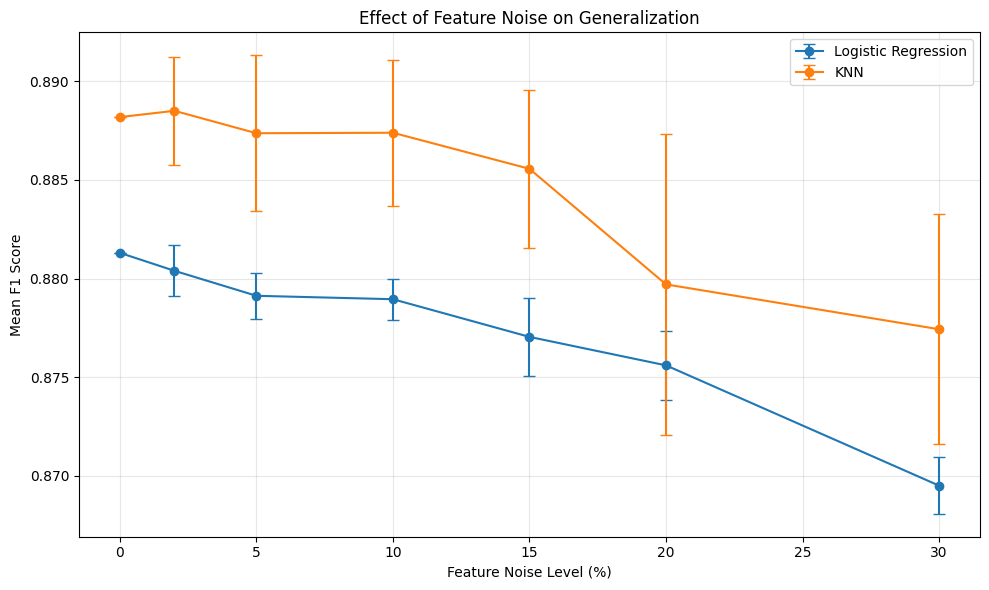

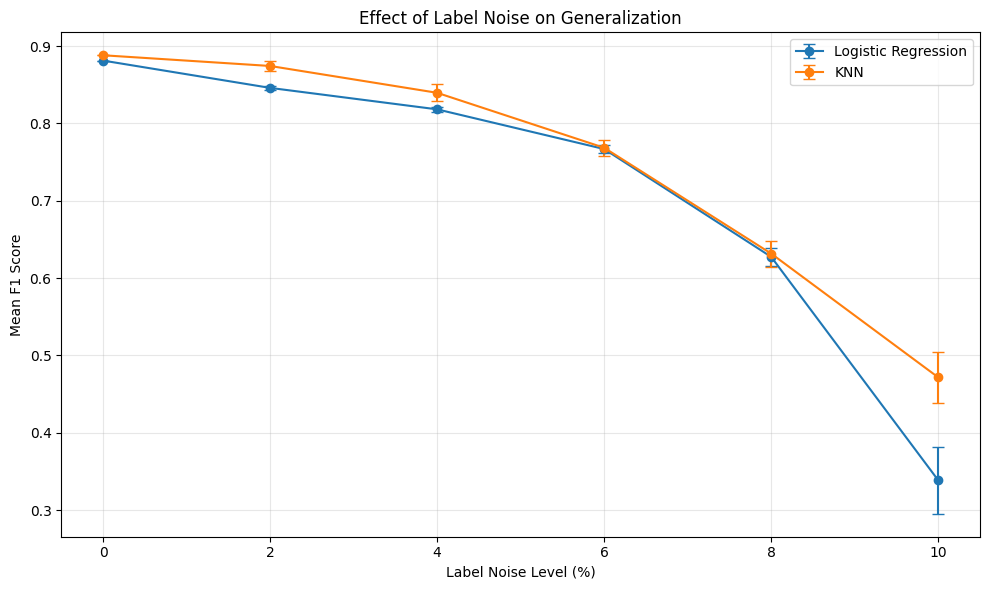

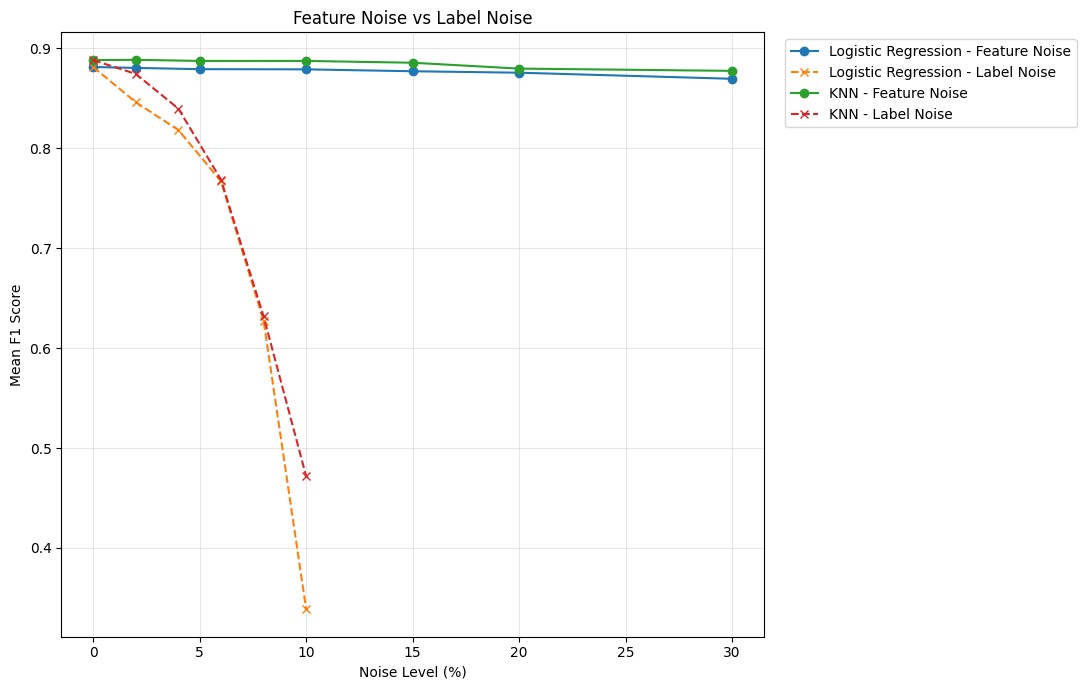

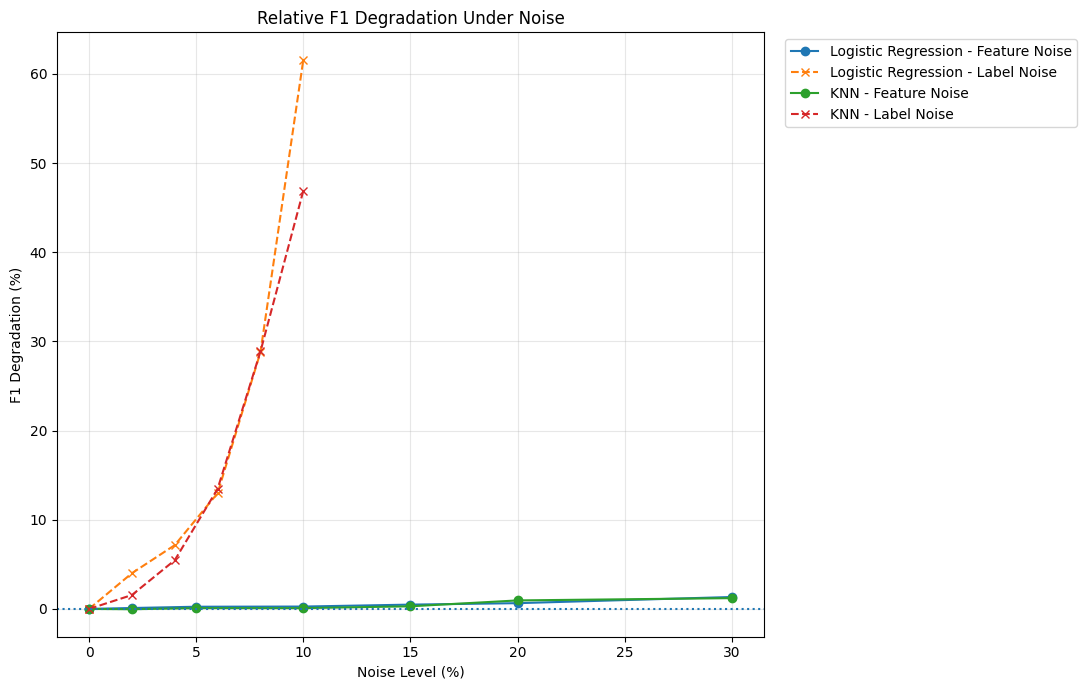

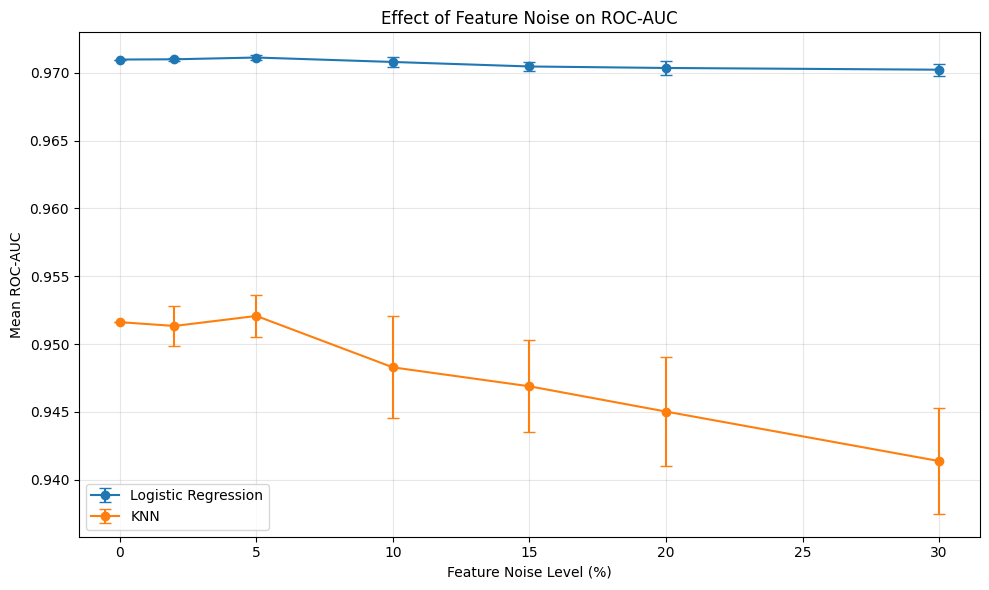

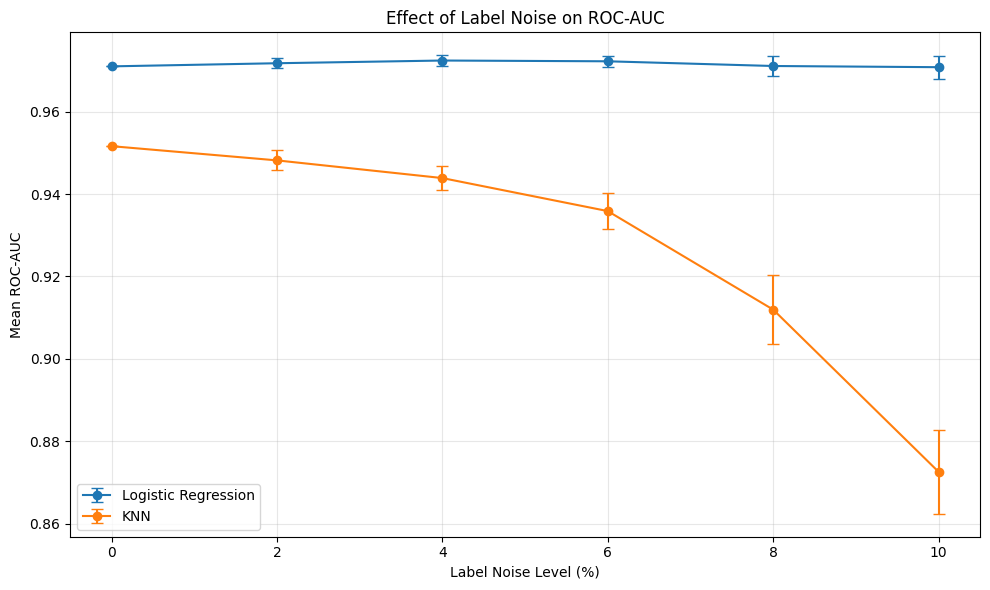

In [24]:
# ============================================================
# 19. F1 DEGRADATION
# ============================================================
degradation_summary = (
    flat_summary
    .merge(
        baseline_f1,
        on="Model",
        how="left"
    )
)

degradation_summary[
    "F1_Degradation_Percent"
] = (
    (
        degradation_summary[
            "Baseline_F1"
        ]
        -
        degradation_summary[
            "F1_Mean"
        ]
    )
    /
    degradation_summary[
        "Baseline_F1"
    ]
    * 100
)


print("\n" + "=" * 80)
print("[19] RELATIVE F1 DEGRADATION")
print("=" * 80)

display(
    degradation_summary
    .sort_values(
        [
            "Noise_Type",
            "Noise_Level",
            "Model"
        ]
    )
    [
        [
            "Noise_Type",
            "Noise_Percentage",
            "Model",
            "Baseline_F1",
            "F1_Mean",
            "F1_SD",
            "F1_Degradation_Percent"
        ]
    ]
    .round(4)
)


# ============================================================
# 19. GRAPH 1
# FEATURE NOISE → F1
# ============================================================

plt.figure(
    figsize=(10, 6)
)

for model_name in models.keys():

    data = flat_summary[
        (
            flat_summary[
                "Noise_Type"
            ]
            == "Feature Noise"
        )
        &
        (
            flat_summary[
                "Model"
            ]
            == model_name
        )
    ].sort_values(
        "Noise_Level"
    )

    plt.errorbar(
        data[
            "Noise_Percentage"
        ],
        data[
            "F1_Mean"
        ],
        yerr=data[
            "F1_SD"
        ],
        marker="o",
        capsize=4,
        label=model_name
    )

plt.xlabel(
    "Feature Noise Level (%)"
)

plt.ylabel(
    "Mean F1 Score"
)

plt.title(
    "Effect of Feature Noise on Generalization"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 20. GRAPH 2
# LABEL NOISE → F1
# ============================================================

plt.figure(
    figsize=(10, 6)
)

for model_name in models.keys():

    data = flat_summary[
        (
            flat_summary[
                "Noise_Type"
            ]
            == "Label Noise"
        )
        &
        (
            flat_summary[
                "Model"
            ]
            == model_name
        )
    ].sort_values(
        "Noise_Level"
    )

    plt.errorbar(
        data[
            "Noise_Percentage"
        ],
        data[
            "F1_Mean"
        ],
        yerr=data[
            "F1_SD"
        ],
        marker="o",
        capsize=4,
        label=model_name
    )

plt.xlabel(
    "Label Noise Level (%)"
)

plt.ylabel(
    "Mean F1 Score"
)

plt.title(
    "Effect of Label Noise on Generalization"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 21. GRAPH 3
# FEATURE NOISE VS LABEL NOISE
# ============================================================

plt.figure(
    figsize=(11, 7)
)

for model_name in models.keys():

    feature_data = flat_summary[
        (
            flat_summary[
                "Noise_Type"
            ]
            == "Feature Noise"
        )
        &
        (
            flat_summary[
                "Model"
            ]
            == model_name
        )
    ].sort_values(
        "Noise_Level"
    )

    label_data = flat_summary[
        (
            flat_summary[
                "Noise_Type"
            ]
            == "Label Noise"
        )
        &
        (
            flat_summary[
                "Model"
            ]
            == model_name
        )
    ].sort_values(
        "Noise_Level"
    )

    plt.plot(
        feature_data[
            "Noise_Percentage"
        ],
        feature_data[
            "F1_Mean"
        ],
        marker="o",
        label=(
            f"{model_name} - "
            f"Feature Noise"
        )
    )

    plt.plot(
        label_data[
            "Noise_Percentage"
        ],
        label_data[
            "F1_Mean"
        ],
        marker="x",
        linestyle="--",
        label=(
            f"{model_name} - "
            f"Label Noise"
        )
    )

plt.xlabel(
    "Noise Level (%)"
)

plt.ylabel(
    "Mean F1 Score"
)

plt.title(
    "Feature Noise vs Label Noise"
)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 22. GRAPH 4
# RELATIVE F1 DEGRADATION
# ============================================================

plt.figure(
    figsize=(11, 7)
)

for model_name in models.keys():

    for noise_type, linestyle, marker in [

        (
            "Feature Noise",
            "-",
            "o"
        ),

        (
            "Label Noise",
            "--",
            "x"
        )
    ]:

        data = degradation_summary[
            (
                degradation_summary[
                    "Noise_Type"
                ]
                == noise_type
            )
            &
            (
                degradation_summary[
                    "Model"
                ]
                == model_name
            )
        ].sort_values(
            "Noise_Level"
        )

        plt.plot(
            data[
                "Noise_Percentage"
            ],
            data[
                "F1_Degradation_Percent"
            ],
            linestyle=linestyle,
            marker=marker,
            label=(
                f"{model_name} - "
                f"{noise_type}"
            )
        )

plt.axhline(
    0,
    linestyle=":"
)

plt.xlabel(
    "Noise Level (%)"
)

plt.ylabel(
    "F1 Degradation (%)"
)

plt.title(
    "Relative F1 Degradation Under Noise"
)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 23. GRAPH 5
# FEATURE NOISE → ROC-AUC
# ============================================================

plt.figure(
    figsize=(10, 6)
)

for model_name in models.keys():

    data = flat_summary[
        (
            flat_summary[
                "Noise_Type"
            ]
            == "Feature Noise"
        )
        &
        (
            flat_summary[
                "Model"
            ]
            == model_name
        )
    ].sort_values(
        "Noise_Level"
    )

    plt.errorbar(
        data[
            "Noise_Percentage"
        ],
        data[
            "ROC_AUC_Mean"
        ],
        yerr=data[
            "ROC_AUC_SD"
        ],
        marker="o",
        capsize=4,
        label=model_name
    )

plt.xlabel(
    "Feature Noise Level (%)"
)

plt.ylabel(
    "Mean ROC-AUC"
)

plt.title(
    "Effect of Feature Noise on ROC-AUC"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 24. GRAPH 6
# LABEL NOISE → ROC-AUC
# ============================================================

plt.figure(
    figsize=(10, 6)
)

for model_name in models.keys():

    data = flat_summary[
        (
            flat_summary[
                "Noise_Type"
            ]
            == "Label Noise"
        )
        &
        (
            flat_summary[
                "Model"
            ]
            == model_name
        )
    ].sort_values(
        "Noise_Level"
    )

    plt.errorbar(
        data[
            "Noise_Percentage"
        ],
        data[
            "ROC_AUC_Mean"
        ],
        yerr=data[
            "ROC_AUC_SD"
        ],
        marker="o",
        capsize=4,
        label=model_name
    )

plt.xlabel(
    "Label Noise Level (%)"
)

plt.ylabel(
    "Mean ROC-AUC"
)

plt.title(
    "Effect of Label Noise on ROC-AUC"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()

### 20. Label-Distribution Check


In [25]:
# ============================================================
# 20. LABEL-DISTRIBUTION CHECK
# ============================================================
print("\n" + "=" * 80)
print("[20] LABEL DISTRIBUTION DURING EXPERIMENT")
print("=" * 80)

label_distribution = (
    label_results_df
    .groupby(["Noise_Percentage", "Repetition"])[
        ["Actual_Flipped", "Train_Class_0", "Train_Class_1"]
    ]
    .first()
    .reset_index()
    .sort_values(["Noise_Percentage", "Repetition"])
)

display(label_distribution.round(2))

original_class_0 = int((y_train == 0).sum())
original_class_1 = int((y_train == 1).sum())

assert (label_distribution["Train_Class_0"] == original_class_0).all()
assert (label_distribution["Train_Class_1"] == original_class_1).all()

print(
    f"\n✓ Class counts preserved at every label-noise level: "
    f"class 0 = {original_class_0}, class 1 = {original_class_1}"
)


[20] LABEL DISTRIBUTION DURING EXPERIMENT


,Noise_Percentage,Repetition,Actual_Flipped,Train_Class_0,Train_Class_1
0,0.0,1,0,13007,1311
1,0.0,2,0,13007,1311
2,0.0,3,0,13007,1311
3,0.0,4,0,13007,1311
4,0.0,5,0,13007,1311
5,0.0,6,0,13007,1311
6,0.0,7,0,13007,1311
7,0.0,8,0,13007,1311
8,0.0,9,0,13007,1311
9,0.0,10,0,13007,1311



✓ Class counts preserved at every label-noise level: class 0 = 13007, class 1 = 1311


### 21. Model-Wise F1 Degradation Summary


In [26]:
# ============================================================
# 21. MODEL-WISE F1 DEGRADATION SUMMARY
# ============================================================
print("\n" + "=" * 80)
print("[21] MODEL-WISE F1 DEGRADATION SUMMARY")
print("=" * 80)

for noise_type in [
    "Feature Noise",
    "Label Noise"
]:

    print(
        f"\n{noise_type}"
    )

    max_level = (
        degradation_summary[
            degradation_summary[
                "Noise_Type"
            ]
            == noise_type
        ][
            "Noise_Level"
        ].max()
    )

    data = degradation_summary[
        (
            degradation_summary[
                "Noise_Type"
            ]
            == noise_type
        )
        &
        (
            degradation_summary[
                "Noise_Level"
            ]
            == max_level
        )
    ].copy()

    data = data.sort_values(
        "F1_Degradation_Percent"
    )

    display(
        data[
            [
                "Model",
                "F1_Mean",
                "F1_SD",
                "F1_Degradation_Percent",
                "ROC_AUC_Mean"
            ]
        ]
        .round(4)
    )


[21] MODEL-WISE F1 DEGRADATION SUMMARY

Feature Noise


,Model,F1_Mean,F1_SD,F1_Degradation_Percent,ROC_AUC_Mean
12,KNN,0.8774,0.0058,1.2103,0.9414
13,Logistic Regression,0.8695,0.0014,1.3385,0.9702



Label Noise


,Model,F1_Mean,F1_SD,F1_Degradation_Percent,ROC_AUC_Mean
24,KNN,0.4717,0.0331,46.8880,0.8725
25,Logistic Regression,0.3387,0.0433,61.5735,0.9708


### 22. Save Raw Experimental Results


In [27]:
# ============================================================
# 22. SAVE RAW EXPERIMENTAL RESULTS
# ============================================================
all_results_df.to_csv(
    RESULTS_DIR / "htru2_experiment2_all_results.csv",
    index=False
)

feature_results_df.to_csv(
    RESULTS_DIR / "htru2_experiment2_feature_noise.csv",
    index=False
)

label_results_df.to_csv(
    RESULTS_DIR / "htru2_experiment2_label_noise.csv",
    index=False
)

### 23. Save Summary Results


In [28]:
# ============================================================
# 23. SAVE SUMMARY RESULTS
# ============================================================
flat_summary.to_csv(
    RESULTS_DIR / "htru2_experiment2_summary.csv",
    index=False
)

degradation_summary.to_csv(
    RESULTS_DIR / "htru2_experiment2_degradation.csv",
    index=False
)

label_verification_df.to_csv(
    RESULTS_DIR / "htru2_experiment2_label_verification.csv",
    index=False
)

baseline_df.to_csv(
    RESULTS_DIR / "htru2_experiment2_baseline.csv",
    index=False
)

In [29]:
# ============================================================
# 24. LABEL-NOISE TRANSITION DIAGNOSTIC
# ============================================================

TRANSITION_NOISE_LEVELS = [0.06, 0.08, 0.085, 0.09, 0.095, 0.10]
TRANSITION_REPETITIONS = 10

transition_results = []

total_runs = (
    len(TRANSITION_NOISE_LEVELS)
    * TRANSITION_REPETITIONS
    * len(models)
)
run_number = 0

print("=" * 70)
print("LABEL-NOISE TRANSITION DIAGNOSTIC")
print("=" * 70)
print(
    "Noise levels:",
    [f"{x*100:g}%" for x in TRANSITION_NOISE_LEVELS]
)
print(f"Repetitions: {TRANSITION_REPETITIONS}")
print(f"Models: {list(models.keys())}")
print(f"Total model trainings: {total_runs}")
print("=" * 70)

for noise_level in TRANSITION_NOISE_LEVELS:

    print(f"\n{'=' * 70}")
    print(f"TRANSITION LEVEL: {noise_level * 100:g}%")
    print(f"{'=' * 70}")

    for repetition in range(TRANSITION_REPETITIONS):

        seed = RANDOM_STATE + repetition + int(noise_level * 10000)

        print(
            f"\n  Repetition {repetition + 1}/{TRANSITION_REPETITIONS} "
            f"| Seed: {seed}"
        )

        y_train_noisy = add_symmetric_label_noise(
            y_train,
            noise_level,
            random_state=seed
        )

        changed = y_train_noisy.values != y_train.values
        actual_flipped = changed.sum()

        original_pulsars = y_train.values == 1
        pulsar_count = original_pulsars.sum()
        pulsars_flipped = (changed & original_pulsars).sum()
        pulsars_surviving = pulsar_count - pulsars_flipped

        print(
            f"  Labels changed: {actual_flipped}/{len(y_train)} "
            f"({actual_flipped / len(y_train) * 100:.2f}%)"
        )
        print(
            f"  Original pulsars: {pulsar_count} | "
            f"Surviving: {pulsars_surviving} | "
            f"Survival: {pulsars_surviving / pulsar_count * 100:.2f}%"
        )

        for model_name, model in models.items():

            run_number += 1
            print(
                f"    [{run_number}/{total_runs}] "
                f"Training {model_name}..."
            )

            results = evaluate_model(
                model,
                X_train,
                y_train_noisy,
                X_test,
                y_test
            )

            predictions = model.predict(X_test)

            tn, fp, fn, tp = confusion_matrix(
                y_test,
                predictions,
                labels=[0, 1]
            ).ravel()

            transition_results.append({
                "Noise_Type": "Label Noise",
                "Noise_Percentage": noise_level * 100,
                "Noise_Level": noise_level,
                "Repetition": repetition + 1,
                "Seed": seed,
                "Model": model_name,
                "Actual_Flipped": actual_flipped,
                "Original_Pulsar_Count": pulsar_count,
                "Pulsars_Flipped": pulsars_flipped,
                "Pulsars_Surviving": pulsars_surviving,
                "Pulsar_Survival_%": pulsars_surviving / pulsar_count * 100,
                "Pulsar_Flip_%": pulsars_flipped / pulsar_count * 100,
                "True_Negatives": tn,
                "False_Positives": fp,
                "False_Negatives": fn,
                "True_Positives": tp,
                "Predicted_Positive": int(fp + tp),
                "Predicted_Negative": int(tn + fn),
                **results
            })

            print(
                f"    ✓ {model_name} completed | "
                f"F1={results['F1']:.4f} | "
                f"Recall={results['Recall']:.4f} | "
                f"ROC-AUC={results['ROC-AUC']:.4f}"
            )

        print(
            f"  ✓ Repetition {repetition + 1}/"
            f"{TRANSITION_REPETITIONS} completed"
        )

transition_results_df = pd.DataFrame(transition_results)

print("\n" + "=" * 70)
print("TRANSITION DIAGNOSTIC COMPLETED")
print("=" * 70)
print(f"Rows generated: {len(transition_results_df)}")
print(f"Expected rows: {total_runs}")
print("=" * 70)

LABEL-NOISE TRANSITION DIAGNOSTIC
Noise levels: ['6%', '8%', '8.5%', '9%', '9.5%', '10%']
Repetitions: 10
Models: ['Logistic Regression', 'KNN']
Total model trainings: 120

TRANSITION LEVEL: 6%

  Repetition 1/10 | Seed: 642
  Labels changed: 858/14318 (5.99%)
  Original pulsars: 1311 | Surviving: 882 | Survival: 67.28%
    [1/120] Training Logistic Regression...
    ✓ Logistic Regression completed | F1=0.7617 | Recall=0.6189 | ROC-AUC=0.9733
    [2/120] Training KNN...
    ✓ KNN completed | F1=0.7650 | Recall=0.6402 | ROC-AUC=0.9381
  ✓ Repetition 1/10 completed

  Repetition 2/10 | Seed: 643
  Labels changed: 858/14318 (5.99%)
  Original pulsars: 1311 | Surviving: 882 | Survival: 67.28%
    [3/120] Training Logistic Regression...
    ✓ Logistic Regression completed | F1=0.7640 | Recall=0.6220 | ROC-AUC=0.9693
    [4/120] Training KNN...
    ✓ KNN completed | F1=0.7569 | Recall=0.6311 | ROC-AUC=0.9358
  ✓ Repetition 2/10 completed

  Repetition 3/10 | Seed: 644
  Labels changed: 858/1

In [30]:
# ============================================================
# 25. TRANSITION-RESULT SCHEMA VALIDATION
# ============================================================

assert required_common_columns.union(required_transition_columns).issubset(
    transition_results_df.columns
), (
    "Transition-result schema is missing: "
    + str(sorted(
        required_common_columns.union(required_transition_columns)
        - set(transition_results_df.columns)
    ))
)
print("✓ Transition result schema validated.")

✓ Transition result schema validated.


In [31]:
# ============================================================
# 26. TRANSITION SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("[26] LABEL-NOISE TRANSITION SUMMARY")
print("=" * 80)


transition_summary = (
    transition_results_df
    .groupby(
        [
            "Noise_Percentage",
            "Model"
        ]
    )
    .agg(

        F1_Mean=(
            "F1",
            "mean"
        ),

        F1_SD=(
            "F1",
            "std"
        ),

        Precision_Mean=(
            "Precision",
            "mean"
        ),

        Precision_SD=(
            "Precision",
            "std"
        ),

        Recall_Mean=(
            "Recall",
            "mean"
        ),

        Recall_SD=(
            "Recall",
            "std"
        ),

        ROC_AUC_Mean=(
            "ROC-AUC",
            "mean"
        ),

        ROC_AUC_SD=(
            "ROC-AUC",
            "std"
        ),

        Accuracy_Mean=(
            "Accuracy",
            "mean"
        ),

        Accuracy_SD=(
            "Accuracy",
            "std"
        ),

        Predicted_Positive_Mean=(
            "Predicted_Positive",
            "mean"
        ),

        Predicted_Positive_SD=(
            "Predicted_Positive",
            "std"
        ),

        Pulsar_Survival_Mean=(
            "Pulsar_Survival_%",
            "mean"
        ),

        Pulsar_Flip_Mean=(
            "Pulsar_Flip_%",
            "mean"
        )

    )
    .reset_index()
)


display(
    transition_summary
    .round(4)
)


[26] LABEL-NOISE TRANSITION SUMMARY


,Noise_Percentage,Model,F1_Mean,F1_SD,Precision_Mean,Precision_SD,Recall_Mean,Recall_SD,ROC_AUC_Mean,ROC_AUC_SD,Accuracy_Mean,Accuracy_SD,Predicted_Positive_Mean,Predicted_Positive_SD,Pulsar_Survival_Mean,Pulsar_Flip_Mean
0,6.0,KNN,0.7686,0.0101,0.9462,0.0102,0.6473,0.0138,0.9359,0.0044,0.9643,0.0013,224.4,5.5817,67.2769,32.7231
1,6.0,Logistic Regression,0.7669,0.0051,0.9908,0.0027,0.6256,0.0070,0.9722,0.0013,0.9652,0.0006,207.1,2.5144,67.2769,32.7231
2,8.0,KNN,0.6317,0.0167,0.9388,0.0158,0.4762,0.0172,0.9119,0.0083,0.9492,0.0019,166.4,5.8157,56.3692,43.6308
3,8.0,Logistic Regression,0.6275,0.0121,1.0000,0.0000,0.4573,0.0128,0.9711,0.0025,0.9503,0.0012,150.0,4.1899,56.3692,43.6308
4,8.5,KNN,0.5983,0.0326,0.9372,0.0154,0.4399,0.0328,0.9019,0.0075,0.9460,0.0033,153.9,9.9939,53.6232,46.3768
5,8.5,Logistic Regression,0.5812,0.0152,1.0000,0.0000,0.4098,0.0150,0.9705,0.0025,0.9459,0.0014,134.4,4.9261,53.6232,46.3768
6,9.0,KNN,0.5755,0.0303,0.9314,0.0161,0.4171,0.0314,0.8960,0.0080,0.9438,0.0028,146.9,11.2788,50.8772,49.1228
7,9.0,Logistic Regression,0.5274,0.0129,1.0000,0.0000,0.3582,0.0119,0.9707,0.0023,0.9412,0.0011,117.5,3.8944,50.8772,49.1228
8,9.5,KNN,0.5122,0.0287,0.9101,0.0179,0.3567,0.0259,0.8844,0.0103,0.9378,0.0026,128.5,7.9477,48.1312,51.8688
9,9.5,Logistic Regression,0.4571,0.0289,1.0000,0.0000,0.2966,0.0240,0.9711,0.0022,0.9356,0.0022,97.3,7.8747,48.1312,51.8688


In [32]:
# ============================================================
# 27. CONFUSION-MATRIX ANALYSIS
# ============================================================

print("\n" + "=" * 80)
print("[27] CONFUSION MATRIX ANALYSIS")
print("=" * 80)


confusion_summary = (
    transition_results_df
    .groupby(
        [
            "Noise_Percentage",
            "Model"
        ]
    )
    [
        [
            "True_Negatives",
            "False_Positives",
            "False_Negatives",
            "True_Positives",
            "Predicted_Positive",
            "Predicted_Negative"
        ]
    ]
    .mean()
    .reset_index()
)


display(
    confusion_summary.round(2)
)


[27] CONFUSION MATRIX ANALYSIS


,Noise_Percentage,Model,True_Negatives,False_Positives,False_Negatives,True_Positives,Predicted_Positive,Predicted_Negative
0,6.0,KNN,3239.9,12.1,115.7,212.3,224.4,3355.6
1,6.0,Logistic Regression,3250.1,1.9,122.8,205.2,207.1,3372.9
2,8.0,KNN,3241.8,10.2,171.8,156.2,166.4,3413.6
3,8.0,Logistic Regression,3252.0,0.0,178.0,150.0,150.0,3430.0
4,8.5,KNN,3242.4,9.6,183.7,144.3,153.9,3426.1
5,8.5,Logistic Regression,3252.0,0.0,193.6,134.4,134.4,3445.6
6,9.0,KNN,3241.9,10.1,191.2,136.8,146.9,3433.1
7,9.0,Logistic Regression,3252.0,0.0,210.5,117.5,117.5,3462.5
8,9.5,KNN,3240.5,11.5,211.0,117.0,128.5,3451.5
9,9.5,Logistic Regression,3252.0,0.0,230.7,97.3,97.3,3482.7


In [34]:
# ============================================================
# 28. FINAL ANALYSIS
# ============================================================
#
# This cell performs analysis only.
# It does not run any additional model training.
# It uses the results already computed in:
#     flat_summary
#     degradation_summary
#     transition_summary
# ============================================================

print("\n" + "=" * 80)
print("[28] FINAL ANALYSIS")
print("=" * 80)


# ------------------------------------------------------------
# 1. Final baseline performance
# ------------------------------------------------------------

print("\n--- BASELINE PERFORMANCE ---")

baseline_display = (
    baseline_df
    .copy()
)

display(
    baseline_display.round(4)
)


# ------------------------------------------------------------
# 2. Feature-noise degradation
# ------------------------------------------------------------

print("\n--- FEATURE-NOISE EFFECT ---")

feature_analysis = (
    degradation_summary[
        degradation_summary["Noise_Type"]
        == "Feature Noise"
    ]
    [
        [
            "Noise_Percentage",
            "Model",
            "Baseline_F1",
            "F1_Mean",
            "F1_SD",
            "F1_Degradation_Percent",
            "ROC_AUC_Mean"
        ]
    ]
    .sort_values(
        [
            "Noise_Percentage",
            "Model"
        ]
    )
)

display(
    feature_analysis.round(4)
)


# ------------------------------------------------------------
# 3. Label-noise degradation
# ------------------------------------------------------------

print("\n--- LABEL-NOISE EFFECT ---")

label_analysis = (
    degradation_summary[
        degradation_summary["Noise_Type"]
        == "Label Noise"
    ]
    [
        [
            "Noise_Percentage",
            "Model",
            "Baseline_F1",
            "F1_Mean",
            "F1_SD",
            "F1_Degradation_Percent",
            "ROC_AUC_Mean"
        ]
    ]
    .sort_values(
        [
            "Noise_Percentage",
            "Model"
        ]
    )
)

display(
    label_analysis.round(4)
)


# ------------------------------------------------------------
# 4. Compare the two noise types at the same nominal 10% level
# ------------------------------------------------------------

print("\n--- 10% FEATURE NOISE vs 10% LABEL NOISE ---")

comparison_10 = (
    degradation_summary[
        (
            degradation_summary["Noise_Percentage"]
            == 10
        )
    ]
    [
        [
            "Noise_Type",
            "Model",
            "Baseline_F1",
            "F1_Mean",
            "F1_SD",
            "F1_Degradation_Percent",
            "Recall_Mean",
            "ROC_AUC_Mean"
        ]
    ]
    .sort_values(
        [
            "Model",
            "Noise_Type"
        ]
    )
)

display(
    comparison_10.round(4)
)


# ------------------------------------------------------------
# 5. Calculate the difference in relative F1 degradation
#
# Positive value means label noise caused more degradation
# than feature noise at the same 10% nominal level.
# ------------------------------------------------------------

print("\n--- ADDITIONAL 10% COMPARISON ---")

comparison_pivot = (
    comparison_10
    .pivot(
        index="Model",
        columns="Noise_Type",
        values="F1_Degradation_Percent"
    )
    .reset_index()
)

comparison_pivot["Additional_Degradation_From_Label_Noise"] = (
    comparison_pivot["Label Noise"]
    -
    comparison_pivot["Feature Noise"]
)

display(
    comparison_pivot.round(4)
)


# ------------------------------------------------------------
# 6. Transition diagnostic
# ------------------------------------------------------------

print("\n--- LABEL-NOISE TRANSITION: 6%, 8%, 8.5%, 9%, 9.5%, 10% ---")

transition_display = (
    transition_summary[
        [
            "Noise_Percentage",
            "Model",
            "F1_Mean",
            "F1_SD",
            "Recall_Mean",
            "ROC_AUC_Mean",
            "Accuracy_Mean",
            "Predicted_Positive_Mean",
            "Pulsar_Survival_Mean",
            "Pulsar_Flip_Mean"
        ]
    ]
    .sort_values(
        [
            "Noise_Percentage",
            "Model"
        ]
    )
)

display(
    transition_display.round(4)
)


# ------------------------------------------------------------
# 7. Calculate F1 change from 6% → 10%
# ------------------------------------------------------------

print("\n--- F1 CHANGE FROM 6% TO 10% LABEL NOISE ---")

transition_pivot = (
    transition_summary
    .pivot(
        index="Model",
        columns="Noise_Percentage",
        values="F1_Mean"
    )
)

transition_pivot["F1_Change_6_to_10"] = (
    transition_pivot[10.0] - transition_pivot[6.0]
)

transition_pivot["Relative_F1_Change_6_to_10_Percent"] = (
    (transition_pivot[10.0] - transition_pivot[6.0])
    / transition_pivot[6.0]
    * 100
)

display(transition_pivot.round(4))


# ------------------------------------------------------------
# 8. Save final analysis tables
# ------------------------------------------------------------

feature_analysis.to_csv(
    RESULTS_DIR / "htru2_final_feature_noise_analysis.csv",
    index=False
)

label_analysis.to_csv(
    RESULTS_DIR / "htru2_final_label_noise_analysis.csv",
    index=False
)

comparison_10.to_csv(
    RESULTS_DIR / "htru2_final_10pct_noise_comparison.csv",
    index=False
)

comparison_pivot.to_csv(
    RESULTS_DIR / "htru2_final_10pct_degradation_difference.csv",
    index=False
)

transition_display.to_csv(
    RESULTS_DIR / "htru2_final_transition_analysis.csv",
    index=False
)

transition_pivot.to_csv(
    RESULTS_DIR / "htru2_final_transition_change.csv"
)

print("\n" + "=" * 80)
print("FINAL ANALYSIS TABLES SAVED")
print("=" * 80)

print("""
1. htru2_final_feature_noise_analysis.csv
2. htru2_final_label_noise_analysis.csv
3. htru2_final_10pct_noise_comparison.csv
4. htru2_final_10pct_degradation_difference.csv
5. htru2_final_transition_analysis.csv
6. htru2_final_transition_change.csv
""")


[28] FINAL ANALYSIS

--- BASELINE PERFORMANCE ---


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.9796,0.9443,0.8262,0.8813,0.9710
1,KNN,0.9804,0.9329,0.8476,0.8882,0.9516



--- FEATURE-NOISE EFFECT ---


,Noise_Percentage,Model,Baseline_F1,F1_Mean,F1_SD,F1_Degradation_Percent,ROC_AUC_Mean
0,0.0,KNN,0.8882,0.8882,0.0000,0.0000,0.9516
1,0.0,Logistic Regression,0.8813,0.8813,0.0000,0.0000,0.9710
2,2.0,KNN,0.8882,0.8885,0.0027,-0.0358,0.9513
3,2.0,Logistic Regression,0.8813,0.8804,0.0013,0.1034,0.9710
4,5.0,KNN,0.8882,0.8874,0.0040,0.0921,0.9521
5,5.0,Logistic Regression,0.8813,0.8791,0.0012,0.2470,0.9711
6,10.0,KNN,0.8882,0.8874,0.0037,0.0893,0.9483
7,10.0,Logistic Regression,0.8813,0.8790,0.0010,0.2667,0.9708
8,15.0,KNN,0.8882,0.8856,0.0040,0.2950,0.9469
9,15.0,Logistic Regression,0.8813,0.8770,0.0020,0.4833,0.9705



--- LABEL-NOISE EFFECT ---


...


--- LABEL-NOISE TRANSITION: 6%, 8%, 8.5%, 9%, 9.5%, 10% ---


,Noise_Percentage,Model,F1_Mean,F1_SD,Recall_Mean,ROC_AUC_Mean,Accuracy_Mean,Predicted_Positive_Mean,Pulsar_Survival_Mean,Pulsar_Flip_Mean
0,6.0,KNN,0.7686,0.0101,0.6473,0.9359,0.9643,224.4,67.2769,32.7231
1,6.0,Logistic Regression,0.7669,0.0051,0.6256,0.9722,0.9652,207.1,67.2769,32.7231
2,8.0,KNN,0.6317,0.0167,0.4762,0.9119,0.9492,166.4,56.3692,43.6308
3,8.0,Logistic Regression,0.6275,0.0121,0.4573,0.9711,0.9503,150.0,56.3692,43.6308
4,8.5,KNN,0.5983,0.0326,0.4399,0.9019,0.9460,153.9,53.6232,46.3768
5,8.5,Logistic Regression,0.5812,0.0152,0.4098,0.9705,0.9459,134.4,53.6232,46.3768
6,9.0,KNN,0.5755,0.0303,0.4171,0.8960,0.9438,146.9,50.8772,49.1228
7,9.0,Logistic Regression,0.5274,0.0129,0.3582,0.9707,0.9412,117.5,50.8772,49.1228
8,9.5,KNN,0.5122,0.0287,0.3567,0.8844,0.9378,128.5,48.1312,51.8688
9,9.5,Logistic Regression,0.4571,0.0289,0.2966,0.9711,0.9356,97.3,48.1312,51.8688



--- F1 CHANGE FROM 6% TO 10% LABEL NOISE ---


Noise_Percentage,6.0,8.0,8.5,9.0,9.5,10.0,F1_Change_6_to_10,Relative_F1_Change_6_to_10_Percent
Model,,,,,,,,
KNN,0.7686,0.6317,0.5983,0.5755,0.5122,0.4717,-0.2969,-38.6234
Logistic Regression,0.7669,0.6275,0.5812,0.5274,0.4571,0.3387,-0.4283,-55.8435



FINAL ANALYSIS TABLES SAVED

1. htru2_final_feature_noise_analysis.csv
2. htru2_final_label_noise_analysis.csv
3. htru2_final_10pct_noise_comparison.csv
4. htru2_final_10pct_degradation_difference.csv
5. htru2_final_transition_analysis.csv
6. htru2_final_transition_change.csv



[29] FINAL FIGURES


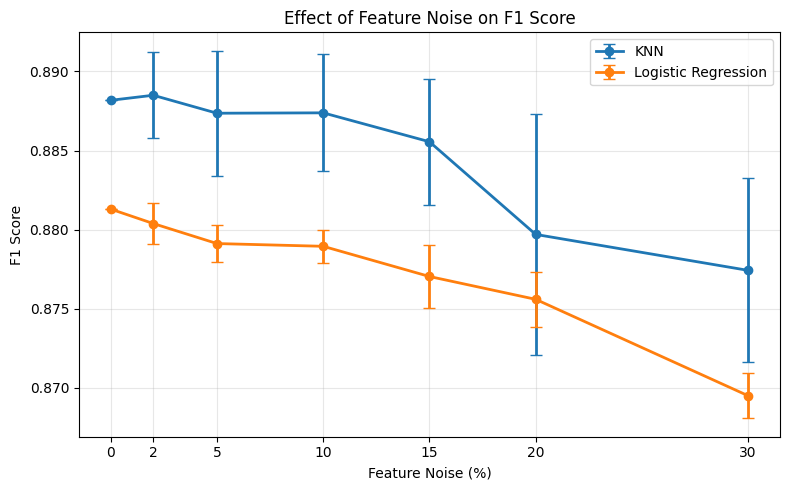

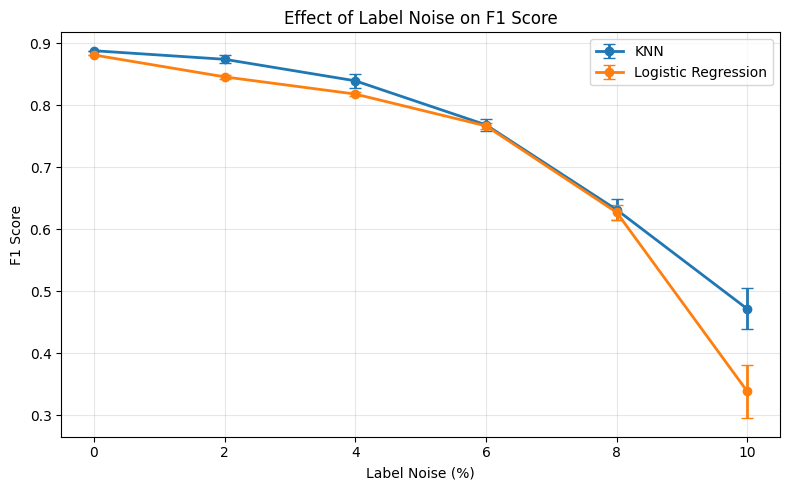

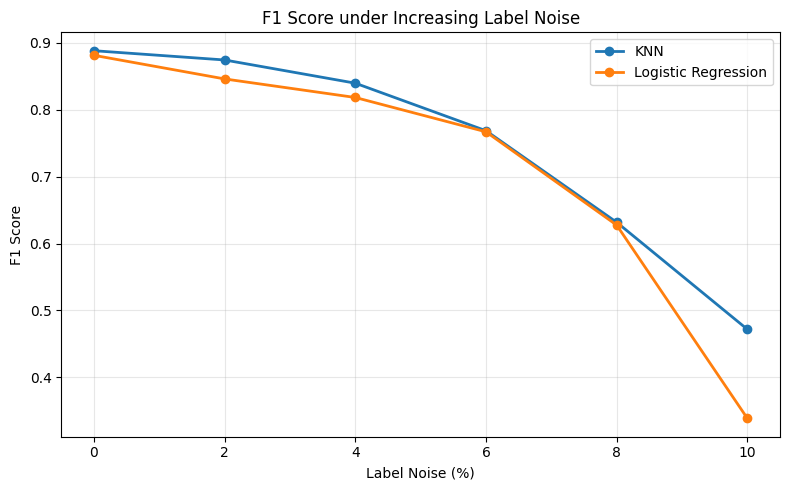

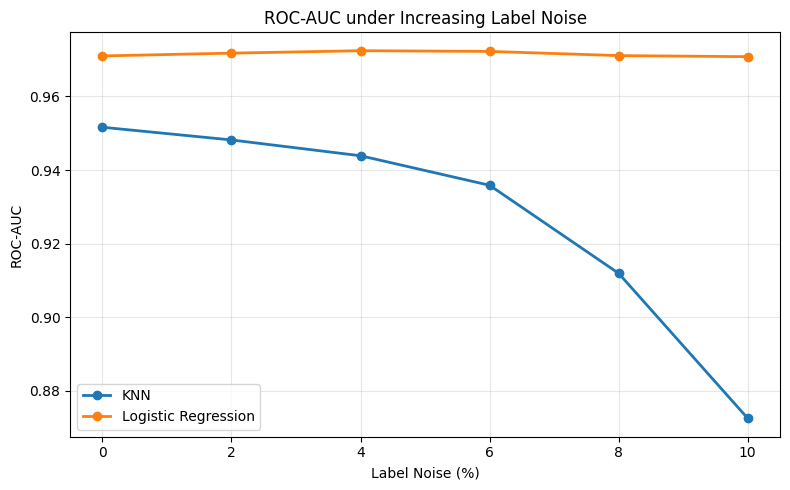

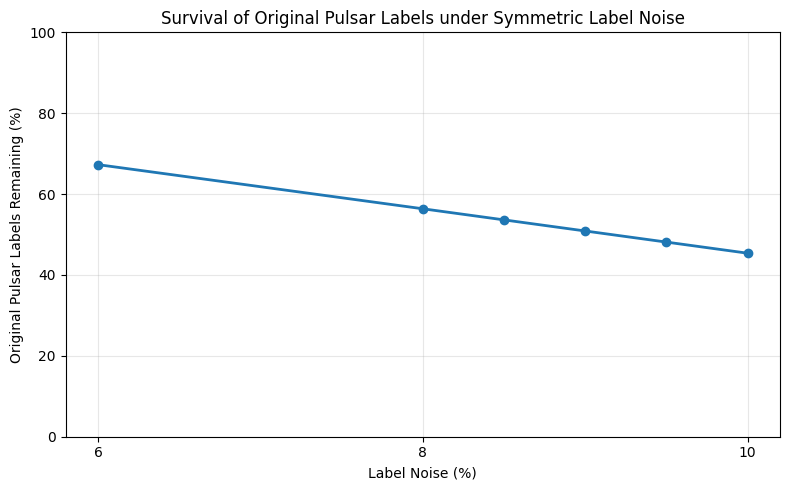


Figures saved:
✓ /content/figures/figure_1_feature_noise_f1.png
✓ /content/figures/figure_2_label_noise_f1.png
✓ /content/figures/figure_3a_label_noise_f1.png
✓ /content/figures/figure_3b_label_noise_roc_auc.png
✓ /content/figures/figure_4_pulsar_label_survival.png

FIGURE GENERATION COMPLETE


In [35]:
# ============================================================
# 29. FINAL FIGURES
# ============================================================
#
# Uses the completed experiment results only.
# No additional model training is performed here.
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("=" * 80)
print("[29] FINAL FIGURES")
print("=" * 80)


# ============================================================
# FIGURE 1 — F1 VERSUS FEATURE NOISE
# ============================================================

plt.figure(figsize=(8, 5))

for model in feature_analysis["Model"].unique():

    data = feature_analysis[
        feature_analysis["Model"] == model
    ].sort_values("Noise_Percentage")

    plt.errorbar(
        data["Noise_Percentage"],
        data["F1_Mean"],
        yerr=data["F1_SD"],
        marker="o",
        capsize=4,
        linewidth=2,
        label=model
    )

plt.xlabel("Feature Noise (%)")
plt.ylabel("F1 Score")
plt.title("Effect of Feature Noise on F1 Score")
plt.xticks([0, 2, 5, 10, 15, 20, 30])
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "figure_1_feature_noise_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 2 — F1 VERSUS LABEL NOISE
# ============================================================

plt.figure(figsize=(8, 5))

for model in label_analysis["Model"].unique():

    data = label_analysis[
        label_analysis["Model"] == model
    ].sort_values("Noise_Percentage")

    plt.errorbar(
        data["Noise_Percentage"],
        data["F1_Mean"],
        yerr=data["F1_SD"],
        marker="o",
        capsize=4,
        linewidth=2,
        label=model
    )

plt.xlabel("Label Noise (%)")
plt.ylabel("F1 Score")
plt.title("Effect of Label Noise on F1 Score")
plt.xticks([0, 2, 4, 6, 8, 10])
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "figure_2_label_noise_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 3 — F1 AND ROC-AUC VERSUS LABEL NOISE
# ============================================================
#
# Separate plots are used so the two metrics remain readable.
# ============================================================

label_model_names = label_analysis["Model"].unique()


# ---- Figure 3A: F1 ----

plt.figure(figsize=(8, 5))

for model in label_model_names:

    data = label_analysis[
        label_analysis["Model"] == model
    ].sort_values("Noise_Percentage")

    plt.plot(
        data["Noise_Percentage"],
        data["F1_Mean"],
        marker="o",
        linewidth=2,
        label=model
    )

plt.xlabel("Label Noise (%)")
plt.ylabel("F1 Score")
plt.title("F1 Score under Increasing Label Noise")
plt.xticks([0, 2, 4, 6, 8, 10])
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "figure_3a_label_noise_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ---- Figure 3B: ROC-AUC ----

plt.figure(figsize=(8, 5))

for model in label_model_names:

    data = label_analysis[
        label_analysis["Model"] == model
    ].sort_values("Noise_Percentage")

    plt.plot(
        data["Noise_Percentage"],
        data["ROC_AUC_Mean"],
        marker="o",
        linewidth=2,
        label=model
    )

plt.xlabel("Label Noise (%)")
plt.ylabel("ROC-AUC")
plt.title("ROC-AUC under Increasing Label Noise")
plt.xticks([0, 2, 4, 6, 8, 10])
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "figure_3b_label_noise_roc_auc.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 4 — ORIGINAL PULSAR LABEL SURVIVAL
# ============================================================

plt.figure(figsize=(8, 5))

survival_data = (
    transition_display[
        ["Noise_Percentage", "Pulsar_Survival_Mean"]
    ]
    .drop_duplicates()
    .sort_values("Noise_Percentage")
)

plt.plot(
    survival_data["Noise_Percentage"],
    survival_data["Pulsar_Survival_Mean"],
    marker="o",
    linewidth=2
)

plt.xlabel("Label Noise (%)")
plt.ylabel("Original Pulsar Labels Remaining (%)")
plt.title("Survival of Original Pulsar Labels under Symmetric Label Noise")
plt.xticks([6, 8, 10])
plt.ylim(0, 100)
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "figure_4_pulsar_label_survival.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# SAVE A COMBINED FIGURE INDEX
# ============================================================

figure_files = [
    "figure_1_feature_noise_f1.png",
    "figure_2_label_noise_f1.png",
    "figure_3a_label_noise_f1.png",
    "figure_3b_label_noise_roc_auc.png",
    "figure_4_pulsar_label_survival.png"
]

print("\nFigures saved:")
for filename in figure_files:
    print("✓", FIGURES_DIR / filename)

print("\n" + "=" * 80)
print("FIGURE GENERATION COMPLETE")
print("=" * 80)

### 30. F1 Variability Across Label-Noise Levels


F1 STANDARD DEVIATION ACROSS LABEL NOISE LEVELS


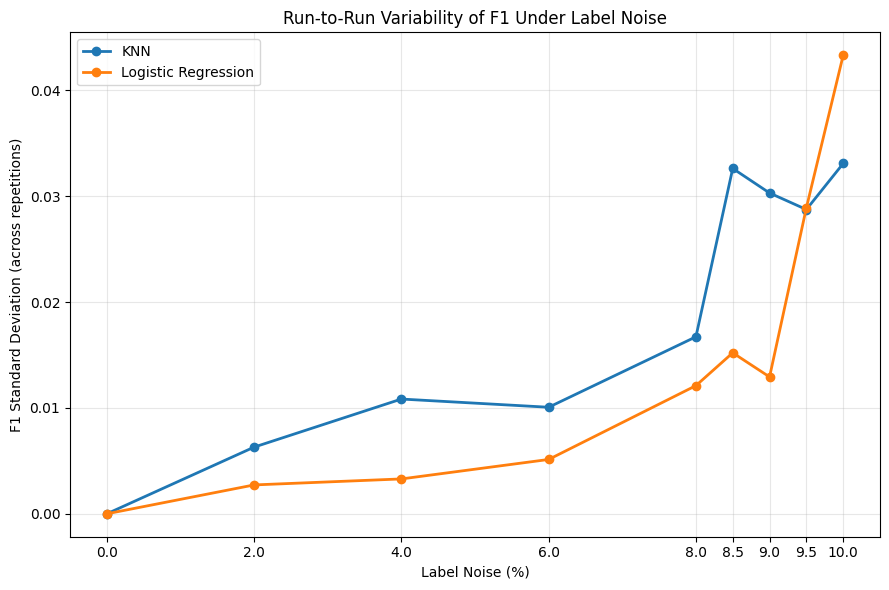


Saved: /content/figures/figure_5_f1_variance_vs_label_noise.png

Combined SD table:
Model                KNN  Logistic Regression
Noise_Percentage                             
0.0               0.0000               0.0000
2.0               0.0063               0.0027
4.0               0.0108               0.0033
6.0               0.0101               0.0051
8.0               0.0167               0.0121
8.5               0.0326               0.0152
9.0               0.0303               0.0129
9.5               0.0287               0.0289
10.0              0.0331               0.0433


In [36]:
# ============================================================
# 30. F1 VARIABILITY ACROSS LABEL-NOISE LEVELS
# ============================================================
#
# Shows variability across repeated noise realizations in addition to mean degradation.
# Combines the main 0–4% grid with the 6–10% transition grid into one continuous curve.
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

print("=" * 80)
print("F1 STANDARD DEVIATION ACROSS LABEL NOISE LEVELS")
print("=" * 80)

# Main-grid points below the transition region
low_range = label_analysis[
    label_analysis["Noise_Percentage"] < 6
][
    ["Noise_Percentage", "Model", "F1_Mean", "F1_SD"]
]

# Transition-region points (6, 8, 8.5, 9, 9.5, 10)
high_range = transition_summary[
    ["Noise_Percentage", "Model", "F1_Mean", "F1_SD"]
]

sd_combined = (
    pd.concat([low_range, high_range], ignore_index=True)
    .sort_values(["Model", "Noise_Percentage"])
)

plt.figure(figsize=(9, 6))

for model_name in sd_combined["Model"].unique():

    data = sd_combined[
        sd_combined["Model"] == model_name
    ].sort_values("Noise_Percentage")

    plt.plot(
        data["Noise_Percentage"],
        data["F1_SD"],
        marker="o",
        linewidth=2,
        label=model_name
    )

plt.xlabel("Label Noise (%)")
plt.ylabel("F1 Standard Deviation (across repetitions)")
plt.title("Run-to-Run Variability of F1 Under Label Noise")
plt.xticks([0, 2, 4, 6, 8, 8.5, 9, 9.5, 10])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "figure_5_f1_variance_vs_label_noise.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:", FIGURES_DIR / "figure_5_f1_variance_vs_label_noise.png")
print("\nCombined SD table:")
print(
    sd_combined
    .pivot(index="Noise_Percentage", columns="Model", values="F1_SD")
    .round(4)
)

In [37]:
# ============================================================
# 31. PAPER TABLES
# ============================================================

print("=" * 80)
print("[31] FINAL PAPER TABLES")
print("=" * 80)


# ============================================================
# TABLE 1 — DATASET / CLASS DISTRIBUTION
# ============================================================

dataset_table = pd.DataFrame({
    "Class": ["Non-Pulsar (0)", "Pulsar (1)", "Total"],
    "Count": [16259, 1639, 17898],
    "Percentage": [
        16259 / 17898 * 100,
        1639 / 17898 * 100,
        100.0
    ]
})

print("\nTABLE 1 — DATASET CLASS DISTRIBUTION")
display(dataset_table.round(2))


# ============================================================
# TABLE 2 — CLEAN BASELINE PERFORMANCE
# ============================================================

baseline_table = baseline_df.copy()

print("\nTABLE 2 — CLEAN BASELINE PERFORMANCE")
display(baseline_table.round(4))


# ============================================================
# TABLE 3 — FEATURE-NOISE RESULTS
# ============================================================

feature_table = feature_analysis.copy()

print("\nTABLE 3 — FEATURE-NOISE RESULTS")
display(feature_table.round(4))


# ============================================================
# TABLE 4 — LABEL-NOISE RESULTS
# ============================================================

label_table = label_analysis.copy()

print("\nTABLE 4 — LABEL-NOISE RESULTS")
display(label_table.round(4))


# ============================================================
# TABLE 5 — LABEL-NOISE TRANSITION
# ============================================================

transition_table = transition_display.copy()

print("\nTABLE 5 — LABEL-NOISE TRANSITION")
display(transition_table.round(4))


# ============================================================
# SAVE TABLES
# ============================================================

dataset_table.to_csv(
    RESULTS_DIR / "table_1_dataset_class_distribution.csv",
    index=False
)

baseline_table.to_csv(
    RESULTS_DIR / "table_2_clean_baseline.csv",
    index=False
)

feature_table.to_csv(
    RESULTS_DIR / "table_3_feature_noise.csv",
    index=False
)

label_table.to_csv(
    RESULTS_DIR / "table_4_label_noise.csv",
    index=False
)

transition_table.to_csv(
    RESULTS_DIR / "table_5_label_noise_transition.csv",
    index=False
)


print("\n" + "=" * 80)
print("ALL FIVE PAPER TABLES SAVED")
print("=" * 80)

[31] FINAL PAPER TABLES

TABLE 1 — DATASET CLASS DISTRIBUTION


,Class,Count,Percentage
0,Non-Pulsar (0),16259,90.84
1,Pulsar (1),1639,9.16
2,Total,17898,100.00



TABLE 2 — CLEAN BASELINE PERFORMANCE


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.9796,0.9443,0.8262,0.8813,0.9710
1,KNN,0.9804,0.9329,0.8476,0.8882,0.9516



TABLE 3 — FEATURE-NOISE RESULTS


...


TABLE 4 — LABEL-NOISE RESULTS


,Noise_Percentage,Model,Baseline_F1,F1_Mean,F1_SD,F1_Degradation_Percent,ROC_AUC_Mean
14,0.0,KNN,0.8882,0.8882,0.0000,0.0000,0.9516
15,0.0,Logistic Regression,0.8813,0.8813,0.0000,0.0000,0.9710
16,2.0,KNN,0.8882,0.8743,0.0063,1.5586,0.9482
17,2.0,Logistic Regression,0.8813,0.8460,0.0027,4.0053,0.9717
18,4.0,KNN,0.8882,0.8396,0.0108,5.4648,0.9439
19,4.0,Logistic Regression,0.8813,0.8183,0.0033,7.1537,0.9724
20,6.0,KNN,0.8882,0.7686,0.0101,13.4653,0.9359
21,6.0,Logistic Regression,0.8813,0.7669,0.0051,12.9765,0.9722
22,8.0,KNN,0.8882,0.6317,0.0167,28.8725,0.9119
23,8.0,Logistic Regression,0.8813,0.6275,0.0121,28.7962,0.9711



TABLE 5 — LABEL-NOISE TRANSITION


,Noise_Percentage,Model,F1_Mean,F1_SD,Recall_Mean,ROC_AUC_Mean,Accuracy_Mean,Predicted_Positive_Mean,Pulsar_Survival_Mean,Pulsar_Flip_Mean
0,6.0,KNN,0.7686,0.0101,0.6473,0.9359,0.9643,224.4,67.2769,32.7231
1,6.0,Logistic Regression,0.7669,0.0051,0.6256,0.9722,0.9652,207.1,67.2769,32.7231
2,8.0,KNN,0.6317,0.0167,0.4762,0.9119,0.9492,166.4,56.3692,43.6308
3,8.0,Logistic Regression,0.6275,0.0121,0.4573,0.9711,0.9503,150.0,56.3692,43.6308
4,8.5,KNN,0.5983,0.0326,0.4399,0.9019,0.9460,153.9,53.6232,46.3768
5,8.5,Logistic Regression,0.5812,0.0152,0.4098,0.9705,0.9459,134.4,53.6232,46.3768
6,9.0,KNN,0.5755,0.0303,0.4171,0.8960,0.9438,146.9,50.8772,49.1228
7,9.0,Logistic Regression,0.5274,0.0129,0.3582,0.9707,0.9412,117.5,50.8772,49.1228
8,9.5,KNN,0.5122,0.0287,0.3567,0.8844,0.9378,128.5,48.1312,51.8688
9,9.5,Logistic Regression,0.4571,0.0289,0.2966,0.9711,0.9356,97.3,48.1312,51.8688



ALL FIVE PAPER TABLES SAVED


In [38]:
# ============================================================
# 32. COMPACT PAPER TABLES
# ============================================================

print("=" * 80)
print("[32] FINAL COMPACT PAPER TABLES")
print("=" * 80)


# ============================================================
# TABLE A — CLEAN BASELINE
# ============================================================

paper_baseline = baseline_table[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ]
].copy()

print("\nTABLE A — CLEAN BASELINE PERFORMANCE")
display(paper_baseline.round(4))


# ============================================================
# TABLE B — FEATURE NOISE ROBUSTNESS
#
# Report selected feature-noise levels for compact presentation.
# ============================================================

feature_selected = feature_table[
    feature_table["Noise_Percentage"].isin([0, 5, 10, 20, 30])
][
    [
        "Noise_Percentage",
        "Model",
        "F1_Mean",
        "F1_SD",
        "F1_Degradation_Percent",
        "ROC_AUC_Mean"
    ]
].copy()

print("\nTABLE B — FEATURE-NOISE ROBUSTNESS")
display(feature_selected.round(4))


# ============================================================
# TABLE C — LABEL NOISE SENSITIVITY
#
# Report every tested label-noise level because the transition is a key result.
# ============================================================

label_selected = label_table[
    [
        "Noise_Percentage",
        "Model",
        "F1_Mean",
        "F1_SD",
        "F1_Degradation_Percent",
        "ROC_AUC_Mean"
    ]
].copy()

print("\nTABLE C — LABEL-NOISE SENSITIVITY")
display(label_selected.round(4))


# ============================================================
# TABLE D — DIRECT 10% COMPARISON
#
# Compare the two noise types at the same nominal 10% level.
# ============================================================

paper_comparison = comparison_10[
    [
        "Noise_Type",
        "Model",
        "F1_Mean",
        "F1_Degradation_Percent",
        "Recall_Mean",
        "ROC_AUC_Mean"
    ]
].copy()

print("\nTABLE D — 10% FEATURE NOISE VS 10% LABEL NOISE")
display(paper_comparison.round(4))


# ============================================================
# TABLE E — LABEL-NOISE TRANSITION
# ============================================================

paper_transition = transition_table[
    [
        "Noise_Percentage",
        "Model",
        "F1_Mean",
        "F1_SD",
        "Recall_Mean",
        "Predicted_Positive_Mean",
        "Pulsar_Survival_Mean"
    ]
].copy()

print("\nTABLE E — LABEL-NOISE TRANSITION")
display(paper_transition.round(4))


# ============================================================
# SAVE FINAL PAPER TABLES
# ============================================================

paper_baseline.to_csv(
    RESULTS_DIR / "paper_table_baseline.csv",
    index=False
)

feature_selected.to_csv(
    RESULTS_DIR / "paper_table_feature_noise.csv",
    index=False
)

label_selected.to_csv(
    RESULTS_DIR / "paper_table_label_noise.csv",
    index=False
)

paper_comparison.to_csv(
    RESULTS_DIR / "paper_table_10pct_comparison.csv",
    index=False
)

paper_transition.to_csv(
    RESULTS_DIR / "paper_table_transition.csv",
    index=False
)


print("\n" + "=" * 80)
print("FINAL PAPER TABLES CREATED")
print("=" * 80)

[32] FINAL COMPACT PAPER TABLES

TABLE A — CLEAN BASELINE PERFORMANCE


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.9796,0.9443,0.8262,0.8813,0.9710
1,KNN,0.9804,0.9329,0.8476,0.8882,0.9516



TABLE B — FEATURE-NOISE ROBUSTNESS


,Noise_Percentage,Model,F1_Mean,F1_SD,F1_Degradation_Percent,ROC_AUC_Mean
0,0.0,KNN,0.8882,0.0000,0.0000,0.9516
1,0.0,Logistic Regression,0.8813,0.0000,0.0000,0.9710
4,5.0,KNN,0.8874,0.0040,0.0921,0.9521
5,5.0,Logistic Regression,0.8791,0.0012,0.2470,0.9711
6,10.0,KNN,0.8874,0.0037,0.0893,0.9483
7,10.0,Logistic Regression,0.8790,0.0010,0.2667,0.9708
10,20.0,KNN,0.8797,0.0076,0.9545,0.9450
11,20.0,Logistic Regression,0.8756,0.0017,0.6470,0.9704
12,30.0,KNN,0.8774,0.0058,1.2103,0.9414
13,30.0,Logistic Regression,0.8695,0.0014,1.3385,0.9702



TABLE C — LABEL-NOISE SENSITIVITY


...


TABLE D — 10% FEATURE NOISE VS 10% LABEL NOISE


,Noise_Type,Model,F1_Mean,F1_Degradation_Percent,Recall_Mean,ROC_AUC_Mean
6,Feature Noise,KNN,0.8874,0.0893,0.8433,0.9483
24,Label Noise,KNN,0.4717,46.8880,0.3195,0.8725
7,Feature Noise,Logistic Regression,0.8790,0.2667,0.8180,0.9708
25,Label Noise,Logistic Regression,0.3387,61.5735,0.2046,0.9708



TABLE E — LABEL-NOISE TRANSITION


,Noise_Percentage,Model,F1_Mean,F1_SD,Recall_Mean,Predicted_Positive_Mean,Pulsar_Survival_Mean
0,6.0,KNN,0.7686,0.0101,0.6473,224.4,67.2769
1,6.0,Logistic Regression,0.7669,0.0051,0.6256,207.1,67.2769
2,8.0,KNN,0.6317,0.0167,0.4762,166.4,56.3692
3,8.0,Logistic Regression,0.6275,0.0121,0.4573,150.0,56.3692
4,8.5,KNN,0.5983,0.0326,0.4399,153.9,53.6232
5,8.5,Logistic Regression,0.5812,0.0152,0.4098,134.4,53.6232
6,9.0,KNN,0.5755,0.0303,0.4171,146.9,50.8772
7,9.0,Logistic Regression,0.5274,0.0129,0.3582,117.5,50.8772
8,9.5,KNN,0.5122,0.0287,0.3567,128.5,48.1312
9,9.5,Logistic Regression,0.4571,0.0289,0.2966,97.3,48.1312



FINAL PAPER TABLES CREATED


In [39]:
# ============================================================
# 33. LEVENE TEST: F1 VARIABILITY AT 6% VS 9% LABEL NOISE
# ============================================================
from pathlib import Path

_repo = Path.cwd().resolve()
if _repo.name == "notebooks":
    _repo = _repo.parent
_figures = _repo / "figures"
_results = _repo / "results"
_figures.mkdir(parents=True, exist_ok=True)
_results.mkdir(parents=True, exist_ok=True)

levene_rows = []
for model_name in transition_results_df["Model"].unique():
    subset = transition_results_df[transition_results_df["Model"] == model_name]
    a = subset.loc[np.isclose(subset["Noise_Level"], 0.06), "F1"].to_numpy()
    b = subset.loc[np.isclose(subset["Noise_Level"], 0.09), "F1"].to_numpy()
    if len(a) < 2 or len(b) < 2:
        continue
    stat, pvalue = levene(a, b, center="median")
    levene_rows.append({
        "Model": model_name,
        "SD_6pct": float(np.std(a, ddof=1)),
        "SD_9pct": float(np.std(b, ddof=1)),
        "Levene_stat": float(stat),
        "Levene_p": float(pvalue),
    })

levene_table = pd.DataFrame(levene_rows)
print("Levene test for F1 variability at 6% versus 9% symmetric label noise")
display(levene_table.round(4))
levene_table.to_csv(_results / "levene_f1_6pct_vs_9pct.csv", index=False)
print(f"Saved {_results / 'levene_f1_6pct_vs_9pct.csv'}")
print(
    "Feature-noise % (Gaussian scale relative to feature std) is not comparable "
    "to label-noise % (fraction of training labels flipped)."
)

Levene test for F1 variability at 6% versus 9% symmetric label noise


,Model,SD_6pct,SD_9pct,Levene_stat,Levene_p
0,Logistic Regression,0.0051,0.0129,4.2573,0.0538
1,KNN,0.0101,0.0303,5.1124,0.0364


Saved /content/results/levene_f1_6pct_vs_9pct.csv
Feature-noise % (Gaussian scale relative to feature std) is not comparable to label-noise % (fraction of training labels flipped).


In [40]:
# ============================================================
# 34. FINAL EXPERIMENT SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("NOISE INVESTIGATION COMPLETE")
print("=" * 80)

print("""
Final experimental design:

Feature noise:
    0%, 2%, 5%, 10%, 15%, 20%, 30%

Label noise:
    0%, 2%, 4%, 6%, 8%, 10%

Transition diagnostic:
    6%, 8%, 8.5%, 9%, 9.5%, 10%

Models:
    Logistic Regression
    KNN

Repetitions:
    10 per condition using different random seeds.
    At 0% noise, all repetitions are identical because no perturbation is applied.

Test set:
    Fixed and clean throughout the experiment.

Label noise:
    Symmetric 0->1 and 1->0 flips preserve the training class counts exactly.

Metrics:
    Accuracy
    Precision
    Recall
    F1
    ROC-AUC

The transition diagnostic provides additional evidence about the change in
performance across the 8%–10% label-noise region.
""")



NOISE INVESTIGATION COMPLETE

Final experimental design:

Feature noise:
    0%, 2%, 5%, 10%, 15%, 20%, 30%

Label noise:
    0%, 2%, 4%, 6%, 8%, 10%

Transition diagnostic:
    6%, 8%, 8.5%, 9%, 9.5%, 10%

Models:
    Logistic Regression
    KNN

Repetitions:
    10 per condition using different random seeds.
    At 0% noise, all repetitions are identical because no perturbation is applied.

Test set:
    Fixed and clean throughout the experiment.

Label noise:
    Symmetric 0->1 and 1->0 flips preserve the training class counts exactly.

Metrics:
    Accuracy
    Precision
    Recall
    F1
    ROC-AUC

The transition diagnostic provides additional evidence about the change in
performance across the 8%–10% label-noise region.

